# Qwen2.5-Omni-3B: understand the idea, then follow the implementation

This notebook has two parts. **[Part 1](#part-1)** explains the problem, earlier methods, the proposed solution, and the results. **[Part 2](#part-2)** teaches the components, formulas, and original implementation step by step. Basic ML, attention, LLM, and PyTorch knowledge is assumed. You can read all saved outputs without running cells.

References open local PDFs or original Python files. For code, use the named symbol and line range in your editor; in VS Code, Ctrl+G jumps to a line. The [paper/code map](paper_code_map.csv) collects those locations.

<a id="part-1"></a>

## Part 1 — Understand the idea

### 1. What problem does the paper want to solve?

Imagine watching a short cooking video. Someone points at a red bowl and says, “Put it in here,” while a timer rings. You ask the assistant, “What should go into the bowl, and what was that sound?” A useful assistant needs to connect the gesture, the words, and the timer. Recognizing each stream separately is not enough: it must know which things happened together. You might then want to hear its answer rather than read it.

This is the setting of **Qwen2.5-Omni**. It accepts text, images, audio, and video, and produces text and speech. “Omni” refers to these input/output abilities; this model does not generate images or video.

There are three connected problems. First, the input formats are different: an image is a grid of pixels, audio is a rapidly changing waveform, and text is a sequence of tokens. The system needs to turn them into information a language model can use. Second, timing matters. A spoken “this one” should connect to the object indicated at that moment, rather than an unrelated frame. Third, generating a good answer and speaking it naturally are different jobs. A responsive system should coordinate them without waiting unnecessarily at every stage.

The paper's goal is therefore broader than adding an audio attachment to a chatbot. It is to build one conversational system that can reason over mixed inputs and deliver a coordinated text/spoken answer. Keep the cooking example in mind: each component in Part 2 solves one part of that request.

**Paper reading:** [Paper §1, PDF pp. 2–3](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=2). Read the motivation for audiovisual synchronization, the relationship between text reasoning and speech, and low-delay interaction. You do not need to understand the architecture details yet.

### 2. What methods already exist, and where do they struggle?

A familiar approach is a pipeline: **automatic speech recognition (ASR) → language model → text-to-speech (TTS)**. ASR turns spoken words into text, the language model answers, and TTS reads the answer aloud. This is useful because each stage can be developed separately. But a transcript is a compressed description of the recording. “Put it in here” does not tell you which bowl the speaker pointed at. A transcript may also omit the timer, laughter, emotion, or a meaningful pause. An ASR mistake can affect the answer, and a speech generator receiving only the final text does not directly see the original context.

These pipelines can be extended with video and can run in a streaming fashion. The paper is not showing that every pipeline is impossible. It is addressing the extra coordination and information loss that arise when independently designed stages exchange only limited information.

A second approach is to build an image-language model or an audio-language model. These extend what the assistant can perceive, but either one alone leaves out part of our example. Even if both encoders are connected to the same language model, simply placing all their features in a list does not explain which video frame belongs with which audio segment. The sequence needs a useful account of space and time.

A third approach is to have one decoder generate both text and audio tokens. That can work, but linguistic reasoning and acoustic generation operate at different rates and require different details. The paper motivates giving them separate responsibilities, while passing rich information between them. Its experiments support the overall system; they do not prove that every alternative decoder design must fail.

The limitations to remember are therefore **information loss, time alignment, and coordination between reasoning and speaking**. These lead directly to the proposed method.

### 3. What method does this paper propose?

The central division is **Thinker–Talker**. Thinker understands the request and generates the text answer. Talker uses information from Thinker to generate speech. A reconstruction stage then turns Talker's discrete speech symbols into a waveform you can play.

![The main responsibilities in the proposed system](figures/idea_overview.png)

Start on the left of the diagram. An audio encoder converts the recording into vectors that retain useful sound information; a vision encoder does the same for images and video frames. Thinker receives those vectors alongside the text. For the cooking example, this is where the spoken instruction, the red bowl, and the timer can influence the same answer.

**TMRoPE** supplies positions that reflect time and image location. You can think of it as giving a feature an address: when it occurred, and where it appeared in a frame. Audio/video features are also arranged in matching time chunks. These two choices help the model associate a gesture with nearby speech. Part 2 explains the actual coordinates and rotations; no formula is needed to follow the idea here.

Thinker generates text and internal representations of its reasoning context. Talker receives text information plus these internal representations, rather than only an isolated final string. This gives speech generation access to both what should be said and contextual information relevant to how to say it. Talker predicts discrete speech-code IDs. **Token2Wav** turns those codes into a spectrogram—a time/frequency description of the sound—and then into waveform samples.

The paper also makes parts of the system suitable for processing blocks rather than waiting for unlimited future context. That matters for interaction delay. There is an implementation distinction to remember: the archived HF convenience function finishes Thinker generation, then Talker generation, then waveform reconstruction. It does not itself deliver those three stages concurrently. We will trace that function in Part 2 rather than equating the paper's streaming design with every public inference wrapper.

**Paper reading:** [Paper §2.1, PDF pp. 3](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=3). Use Figure 2 on PDF page 3 to identify the same responsibilities. Then skim [Paper §2.2, PDF pp. 4](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4)., [Paper §2.3, PDF pp. 4–5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4)., and [Paper §2.4, PDF pp. 5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=5). to see which part addresses representation, generation, and blockwise operation. The formulas and code reading belong to Part 2.

### 4. What are the results?

The paper evaluates several abilities, rather than one universal “intelligence” score: text reasoning, audio understanding, image/video understanding, combined-modality questions, and generated speech. For speech, it also examines whether the spoken content matches the intended words and whether it sounds like the desired speaker.

A few representative results are enough for a first reading:

| Evaluated model and source | Measurement | Reported result | What it tells us |
|---|---|---|---|
| 7B, paper Table 8 | OmniBench average | 56.13% | Performance on a mixed-modality benchmark |
| 3B, archived model card | OmniBench average | 52.19% | Separate evidence for the checkpoint studied here |
| 7B, paper Table 1 | GSM8K | 88.7 | Text reasoning under the reported evaluation settings |
| 7B, paper Table 9 | SEED test-hard word-error rate, ICL → RL | 7.97 → 6.54 | Fewer errors in generated spoken content after the reported training change |

![Reported OmniBench accuracy for the two model sizes](figures/omnibench.png)

ICL and RL are the paper’s labels for in-context-learning speech generation and a reinforcement-learning-refined variant. The table compares those reported variants; it is not a training experiment run here.

The plot compares only the OmniBench averages. It does not mix speech errors with reasoning scores. A word-error rate measures substitutions, missing words, and extra words relative to a reference transcript; lower is better. It is different from naturalness or speaker similarity. A system could pronounce the wrong answer clearly, so speech quality and reasoning need separate evaluations.

These are reported results, not evaluations reproduced by this notebook. The technical report mainly evaluates **7B**, while this guide studies the **3B** configuration and implementation. Do not carry a 7B score over to 3B. Read the [archived 3B model card](sources/checkpoint/README.md) for checkpoint-specific evidence.

The results show that the proposed system handles a broad set of tasks. They do not isolate how much each architectural choice contributes without controlled ablations, and they do not measure the latency of the staged HF wrapper used here. Video OCR and audiovisual collaborative understanding remain difficulties identified in the report.

**Paper reading:** [Paper §5.1, PDF pp. 7–12](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=7). For the numbers above, focus on Table 1 on PDF page 8 and Table 8 on PDF page 12. [Paper §5.2, PDF pp. 12–13](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=12). Read Table 9 on PDF page 13 and the speech-quality discussion on PDF page 13. Ask what each metric measures before comparing its values.

You now have the overall argument: mixed-media conversation needs preserved information, time alignment, and coordinated speech generation; the paper assigns those jobs to connected components. Part 2 follows those connections and explains how they are implemented.


<a id="part-2"></a>

## Part 2 — Understand each component

We now follow the data: prepare inputs, encode sound and vision, attach useful positions, generate an answer, and turn it into speech. Training comes after the mechanisms it trains. The final walkthrough connects the stages.

**Notation and execution.** A tensor shape lists its axis lengths; for example, (B,L,d) means B conversations, L token positions, and d numbers per vector. Keep sequence length separate from vector width. The formulas are explanatory derivations unless explicitly identified as numbered paper equations. Default demonstrations run on CPU, offline, with synthetic inputs and no model weights. Run the setup below once before the demonstrations; full GPU inference stays disabled.

**Sources.** The [paper PDF](sources/paper/qwen2.5-omni-2503.20215v1.pdf) is arXiv:2503.20215v1. Transformers is pinned to cb39f7dd5ba874ee1859b47283b08cd3a6ab5a0d; checkpoint metadata is pinned to f75b40e3da2003cdd6e1829b1f420ca70797c34e. These are the historical sources, not moving branches. See the [manifest](sources/manifest.json) for provenance and checksums.

**Component route:** [Inputs](#component-1) · [Audio](#component-2) · [Vision](#component-3) · [TMRoPE](#component-4) · [Thinker](#component-5) · [Talker](#component-6) · [Token2Wav](#component-7) · [Training](#component-8) · [Complete walkthrough](#component-9)

In [1]:
from pathlib import Path
import json
import socket
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
assert (ROOT / "sources/manifest.json").exists(), "Run from the guide directory."
RUN_FULL_INFERENCE = False
_original_connect = socket.socket.connect

def _offline_connect(self, address):
    if isinstance(address, tuple) and address[0] not in ("127.0.0.1", "::1", "localhost"):
        raise RuntimeError("Default study cells run offline; full inference is explicitly optional.")
    return _original_connect(self, address)

if not RUN_FULL_INFERENCE:
    socket.socket.connect = _offline_connect

plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#253047", "text.color": "#253047"})
COLORS = dict(audio="#b45c24", vision="#386d94", text="#687b36", speech="#9c547c")
rng = np.random.default_rng(7)
results = {}
index = json.loads((ROOT / "sources/code_index.json").read_text())
config = json.loads((ROOT / "sources/checkpoint/config.json").read_text())
manifest = json.loads((ROOT / "sources/manifest.json").read_text())
(ROOT / "figures").mkdir(exist_ok=True)

def finish_figure(fig, name):
    fig.savefig(ROOT / "figures" / (name + ".png"), bbox_inches="tight")
    fig.savefig(ROOT / "figures" / (name + ".svg"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("CPU demonstrations; no pretrained weights; external network disabled.")
print("Paper:", manifest["paper_revision"])
print("Transformers:", manifest["transformers_revision"])

CPU demonstrations; no pretrained weights; external network disabled.
Paper: 2503.20215v1
Transformers: cb39f7dd5ba874ee1859b47283b08cd3a6ab5a0d


<a id="component-1"></a>

### 2.1 Input preparation: reserve the right places for media

#### Problem and mechanism

Before looking inside a neural network, ask what reaches it. In our cooking example, the user supplies a sentence, frames, and sound. The language model cannot consume an image file or a WAV filename directly. The processor makes a coordinated package: token locations that say where each modality belongs, plus the numerical media data that will fill those locations.

Think of placeholders as reserved seats. Reserving one seat for an image that later produces 64 vectors would leave 63 vectors with nowhere to go. The processor therefore needs to know the encoder's output count before Thinker assembles its input.

A user supplies a conversation with media, whereas a Transformer consumes a sequence of vectors. The processor must produce two things that agree: a token sequence with modality placeholders, and feature tensors whose encoded vectors replace those placeholders.

A placeholder identifies a position in the language-model sequence; it is not the raw image or waveform. If an image produces 64 merged vectors, the input needs 64 image-token locations.

#### Follow the interfaces

The chat template turns roles and media markers into text. Modality processors compute audio features and image/video patches. The Omni processor expands markers, tokenizes the expanded text, and combines the tensors.

| Field | Meaning | Typical shape |
|---|---|---|
| input_ids | Text/control/modality IDs | (B,L) |
| attention_mask | Valid language-model positions | (B,L) |
| input_features | Padded audio log-mel features | (N_audio,128,T_pad) |
| feature_attention_mask | Valid audio feature frames | (N_audio,T_pad) |
| pixel_values | Flattened image patches | (N_raw_patches,3×2×14×14) |
| image_grid_thw | Pre-merging image patch grids | (N_images,3) |
| pixel_values_videos | Flattened video patches | Same patch-vector convention |
| video_grid_thw | Video patch grids | (N_videos,3) |
| video_second_per_grid | Seconds per temporal grid step | One value per video |

B is the conversation batch size; L is the expanded sequence length. The number of media inputs need not equal B.

In [Qwen2_5OmniProcessor.__call__](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py) (lines 106–208), follow audio extraction and mask renaming, then image/video grids, then placeholder expansion and tokenization. Video spacing is computed as temporal patch size divided by frames per second.

[Qwen2_5OmniProcessor.replace_multimodal_special_tokens](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py) (lines 210–278) expands each marker to its encoded feature count. In the video-with-audio branch, both modalities are expanded in a common chunk order. The same audio-in-video setting must be used in media preparation, processing, and generation.

#### Shapes must agree before attention

For an already resized 224×224 image, patch size 14 gives a 16×16 spatial grid. Duplicating the image into two frames and using temporal patch size 2 yields **one temporal grid step**. Merging 2×2 patches gives:

$$N_{\rm visual}=\frac{T_gH_gW_g}{m^2}
=\frac{1\cdot16\cdot16}{4}=64.$$

Here T_g, H_g, and W_g are the temporal, height, and width lengths of the patch grid; m=2 is the spatial merge factor. N_visual counts vectors, not individual pixels. There are 256 raw patches in this example, but four adjacent patches become each final vector.

The processor inserts 64 image placeholders; the encoder returns 64 vectors of Thinker width.

For audio, valid mel-frame length T_m determines:

$$T_c=\left\lfloor\frac{T_m-1}{2}\right\rfloor+1,\qquad
T_a=\left\lfloor\frac{T_c-2}{2}\right\rfloor+1.$$

The floor symbol means round down to an integer. T_m is the number of valid spectrogram frames, not the padded tensor length. T_c is the stride-2 convolution output length, and T_a the length after pooling. For 200 frames, these are 100 and 50. Boundary rounding matters; do not replace the integer expressions with T_m/4 everywhere.

The following demonstration varies audio frame counts to show the rounding, then checks the image count. It is useful to predict the result for 199 versus 200 frames before running it. Matching counts is the first correctness condition; matching the order of the vectors will matter in the next components.

#### Paper and source assignment

[Paper §2.2, PDF pp. 4](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). describes representations; [Paper §4.1, PDF pp. 6](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=6). gives the conversation format. Its video examples are conceptual data examples; executable prompts must use the actual archived chat template.

[ProcessorMixin.apply_chat_template](sources/transformers/src/transformers/processing_utils.py) (lines 1373–1566) is the inherited template boundary. [Qwen2VLImageProcessor._preprocess](sources/transformers/src/transformers/models/qwen2_vl/image_processing_qwen2_vl.py) (lines 169–299) arranges pixels into patches. A convenience media-loading helper is not the neural encoder.

**Check.** Why are the audio and language-model masks different?

**Answer.** They mask different sequences: spectrogram frames versus expanded language-model positions.


**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py)
- [sources/transformers/src/transformers/models/qwen2_vl/image_processing_qwen2_vl.py](sources/transformers/src/transformers/models/qwen2_vl/image_processing_qwen2_vl.py)
- [sources/transformers/src/transformers/processing_utils.py](sources/transformers/src/transformers/processing_utils.py)


In [2]:
def audio_lengths(valid_mel_frames):
    after_conv = (np.asarray(valid_mel_frames) - 1) // 2 + 1
    after_pool = (after_conv - 2) // 2 + 1
    return after_conv, after_pool

frames = np.array([4,5,7,8,199,200,201,400])
conv_lengths, token_lengths = audio_lengths(frames)
display(Markdown("| Valid mel frames | After stride-2 conv | Final audio tokens |\n"
                 "|---:|---:|---:|\n" +
                 "\n".join(f"| {a} | {b} | {c} |" for a,b,c in zip(frames,conv_lengths,token_lengths))))
assert token_lengths.tolist() == [1,1,2,2,50,50,50,100]
results["audio_tokens_2s"] = int(audio_lengths(200)[1])
grid = np.array([1,16,16])
results["image_tokens_224"] = int(grid.prod() // 4)
print("224×224 image: grid",grid.tolist(),"→",results["image_tokens_224"],"merged tokens")
display(Markdown("**Read the original chat template:** [tokenizer_config.json](sources/checkpoint/tokenizer_config.json), field `chat_template`. Inspect the modality markers and role delimiters in your editor."))

| Valid mel frames | After stride-2 conv | Final audio tokens |
|---:|---:|---:|
| 4 | 2 | 1 |
| 5 | 3 | 1 |
| 7 | 4 | 2 |
| 8 | 4 | 2 |
| 199 | 100 | 50 |
| 200 | 100 | 50 |
| 201 | 101 | 50 |
| 400 | 200 | 100 |

224×224 image: grid [1, 16, 16] → 64 merged tokens


**Read the original chat template:** [tokenizer_config.json](sources/checkpoint/tokenizer_config.json), field `chat_template`. Inspect the modality markers and role delimiters in your editor.

<a id="component-2"></a>

### 2.2 Audio encoder: turn sound into understanding vectors

#### Why preserve audio information?

Inputs can include speech, music, laughter, alarms, and mixtures. A transcript can discard information needed to answer questions about sound. Thinker's audio path therefore extracts continuous representations rather than first requiring text or speech-codec tokens.

The desired output is a list of vectors describing sound, including more than spoken words. Each vector has 2,048 entries so Thinker can insert it into its own sequence. The encoder's job is to turn a fast waveform into a shorter sequence while retaining useful information.

#### First explain Whisper's architecture and training

The original [Whisper paper](sources/references/whisper-2212.04356v1.pdf), especially the approach/model discussion on PDF pages 3–4, describes an encoder–decoder Transformer trained on large-scale weakly supervised audio/text pairs. Its encoder processes log-mel features through convolutions and self-attention. Its autoregressive text decoder cross-attends to encoder states: while choosing a text token, it can read the audio representations. “Teacher forcing” means supplying the correct previous text tokens during training instead of using the decoder’s own guesses. Predicting the next correct token supplies the learning signal. Special tokens identify tasks and languages; teacher-forced next-token prediction trains transcription and related supervised tasks.

Whisper's encoder is not its text decoder, and neither is merely a mel filter bank. Omni initializes an audio encoder from Whisper-large-v3 and adopts the audio-understanding approach of [Qwen2-Audio](sources/references/qwen2-audio-2407.10759v1.pdf). The encoder connects to Qwen's LLM, replacing the original Whisper decoder as the answering system.

The original Whisper paper predates large-v3. The precise 128-bin feature setting used here is established by the Omni paper/checkpoint, rather than inferred from that earlier paper.

#### Waveform to log-mel features

The paper specifies 16 kHz input, 25 ms windows, 10 ms hops, and 128 mel channels. These correspond to a 400-sample window and 160-sample hop.

An explanatory short-time Fourier transform and mel transform are:

$$S_{k,n}=\sum_{j=0}^{N-1}x[nH+j]w[j]e^{-2\pi i kj/N},
\qquad P_{k,n}=|S_{k,n}|^2,$$

$$M_{b,n}=\sum_kF_{b,k}P_{k,n},\qquad
Z_{b,n}=\log_{10}\max(M_{b,n},\epsilon).$$

x is the waveform, N=400 the window length, H=160 the hop, w the window, F the mel filter bank, and b a mel channel. The mel bank aggregates frequency energy with nonuniform spacing. The logarithm compresses its dynamic range.

Read the equations as a sequence of operations. For each small time window, S measures how much of each frequency is present. Squaring its magnitude gives energy P. A row of F collects energy from nearby frequencies into one mel band M. Taking the logarithm makes quiet and loud signals easier to represent on the same scale. The indices k and n mean frequency bin and time frame; j indexes samples inside a window, and i in the exponential is the imaginary unit. The small positive epsilon prevents taking the logarithm of zero.

For two seconds at 16,000 samples per second, the waveform contains 32,000 samples. A 160-sample hop moves forward by 0.01 seconds, giving about 200 frames. Each frame contains 128 numbers. The exact frame count depends on boundary padding and trimming, so the demonstration states those conventions rather than assuming every STFT returns exactly the same count.

These are teaching equations, not numbered Omni equations. The exact feature extractor also clips the log range and normalizes. Read [WhisperFeatureExtractor._np_extract_fbank_features](sources/transformers/src/transformers/models/whisper/feature_extraction_whisper.py) (lines 108–136) and its PyTorch counterpart. The NumPy demonstration below reproduces the important steps, with its boundary conventions stated.

#### Follow the audio encoder

[Qwen2_5OmniAudioEncoder.__init__](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 851–870) defines a first convolution mapping 128 channels to 1,280 with stride 1, then a second convolution with stride 2. It adds sinusoidal positions, applies 32 encoder layers, average-pools with kernel/stride 2, normalizes, and projects from 1,280 to 2,048.

The general convolution length is:

$$T_{\rm out}=\left\lfloor
\frac{T_{\rm in}+2p-d(k-1)-1}{s}+1\right\rfloor.$$

k is kernel size, p padding, d dilation, and s stride. This explains the integer expressions in [Qwen2_5OmniAudioEncoder._get_feat_extract_output_lengths](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 983–989).

For our 200-frame example, the first convolution preserves time length, the second reduces it to 100, and pooling reduces it to 50. Projection changes the width of each vector, not the number of vectors: (50,1280) becomes (50,2048). Convolutions learn local sound patterns; self-attention lets positions exchange information; pooling shortens the sequence; projection makes the result fit Thinker's interface.

The final representation stride is approximately 40 ms. That is not a 40 ms receptive field: each vector can encode surrounding information within its attention block.

#### Block attention is implemented through packing

In [Qwen2_5OmniAudioEncoder.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 884–942), n_window=100 means input chunks contain n_window×2=200 mel frames, or two seconds. Read these operations:

1. Split valid audio into chunks, including a shorter final chunk.
2. Pad chunks for convolution and derive post-convolution masks.
3. Add local sinusoidal positions.
4. Remove padding and concatenate valid states.
5. Construct cumulative boundaries, cu_seqlens, for attention.
6. Reassemble each audio, pool, normalize, and project.

For example, cumulative boundaries [0,100,200] delimit two post-convolution blocks. They are not timestamps. In [Qwen2_5OmniAudioAttention.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 621–659), inspect how the eager implementation creates a block-diagonal attention mask; compare the SDPA/FlashAttention alternatives.

Attention inside a two-second block is bidirectional. This supports block processing; it is not strictly causal sample-by-sample encoding. Thinker handles longer context after encoding.

The demonstration below starts with a simple mixture of 440 Hz and 880 Hz tones. Expect two bright frequency bands in the spectrogram. It teaches feature extraction, not Whisper's learned representations or recognition accuracy. No encoder weights are loaded.

#### Paper assignment and comprehension check

[Paper §2.2, PDF pp. 4](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). explains the representation; [Paper §2.4, PDF pp. 5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=5). gives the blockwise motivation; [Paper §3, PDF pp. 6](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=6). describes initialization and training.

**Check.** Does this encoder produce Talker's speech tokens?

**Answer.** No. It produces continuous 2,048-dimensional understanding vectors. Talker predicts discrete output codec tokens.


**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)
- [sources/transformers/src/transformers/models/whisper/feature_extraction_whisper.py](sources/transformers/src/transformers/models/whisper/feature_extraction_whisper.py)


Synthetic signal: (32000,) → features: (128, 200) → 50 audio tokens


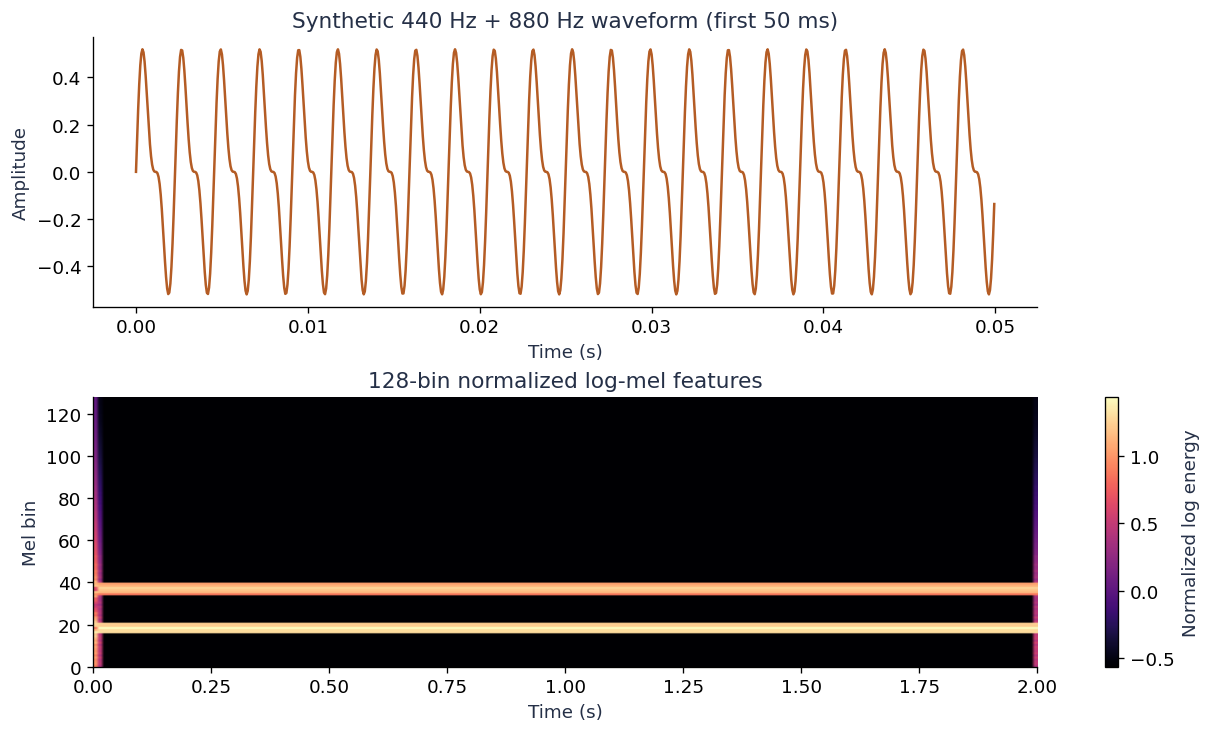

The peaks reflect the two synthetic tones. This is a feature calculation, not a speech-recognition result.

In [3]:
sample_rate = 16000
duration = 2.0
t = np.arange(int(sample_rate*duration)) / sample_rate
wave = 0.4*np.sin(2*np.pi*440*t) + 0.2*np.sin(2*np.pi*880*t)
n_fft, hop = 400,160
centered = np.pad(wave,(n_fft//2,n_fft//2),mode="reflect")
windows = np.lib.stride_tricks.sliding_window_view(centered,n_fft)[::hop]
window = np.hanning(n_fft+1)[:-1]  # periodic Hann
power = np.abs(np.fft.rfft(windows*window,axis=-1))**2
power = power[:-1].T  # Whisper drops the last centered frame

def hz_to_mel(hz):
    hz=np.asarray(hz,dtype=float)
    return np.where(hz<1000,hz/(200/3),15+np.log(np.maximum(hz,1e-12)/1000)/(np.log(6.4)/27))

def mel_to_hz(mel):
    mel=np.asarray(mel,dtype=float)
    return np.where(mel<15,mel*(200/3),1000*np.exp((mel-15)*np.log(6.4)/27))

frequencies=np.fft.rfftfreq(n_fft,1/sample_rate)
edges=mel_to_hz(np.linspace(0,hz_to_mel(sample_rate/2),130))
lower=(frequencies[:,None]-edges[:-2])/(edges[1:-1]-edges[:-2])
upper=(edges[2:]-frequencies[:,None])/(edges[2:]-edges[1:-1])
filters=np.maximum(0,np.minimum(lower,upper))* (2/(edges[2:]-edges[:-2]))
mel=filters.T@power
log_mel=np.log10(np.maximum(mel,1e-10))
features=(np.maximum(log_mel,log_mel.max()-8)+4)/4
assert features.shape==(128,200)
print("Synthetic signal:",wave.shape,"→ features:",features.shape,"→ 50 audio tokens")
fig,axes=plt.subplots(2,1,figsize=(10,6),layout="constrained")
axes[0].plot(t[:800],wave[:800],color=COLORS["audio"])
axes[0].set(title="Synthetic 440 Hz + 880 Hz waveform (first 50 ms)",xlabel="Time (s)",ylabel="Amplitude")
im=axes[1].imshow(features,origin="lower",aspect="auto",extent=(0,2,0,128),cmap="magma")
axes[1].set(title="128-bin normalized log-mel features",xlabel="Time (s)",ylabel="Mel bin")
fig.colorbar(im,ax=axes[1],label="Normalized log energy")
finish_figure(fig,"audio_features")
display(Markdown("The peaks reflect the two synthetic tones. This is a feature calculation, not a speech-recognition result."))

<a id="component-3"></a>

### 2.3 Vision encoder: turn images and frames into vectors

The audio encoder turns time windows into vectors. The vision encoder does the corresponding job for small regions of frames. A whole image collapsed into one vector would make fine spatial relationships difficult to preserve; patch tokens keep separate locations available until learned merging reduces their number.

For the red bowl, the useful information may include shape, color, nearby objects, and a pointing hand. The architecture provides representations from which those relationships can be learned. Patchification alone does not recognize a bowl.

#### Structure and training lineage

The encoder is inherited from [Qwen2.5-VL](sources/references/qwen2.5-vl-2502.13923v1.pdf). It is a Vision Transformer with temporal patchification, rotary positions, mostly spatial-window attention, selected full-attention layers, and a patch merger.

Each Transformer block applies normalized self-attention and an MLP with residual connections. For language alignment, image/text targets can backpropagate a language-model token loss into visual features. Omni describes first fixing the LLM while training adapters/encoders, then joint multimodal training. This does not establish a new Omni-specific classification or contrastive objective. Consult the VL paper's architecture/training sections for its own recipe, and Omni §3 for the disclosed adaptation.

#### Patch embedding is a 3-D convolution

[Qwen2_5_VisionPatchEmbed.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1172–1178) reshapes patch vectors into (N_patches,3,2,14,14), then applies a convolution with kernel and stride (2,14,14).

For already valid frame dimensions:

$$T_g=T_{\rm frames}/2,\quad H_g=H/14,\quad W_g=W/14,
\qquad N_p=T_gH_gW_g.$$

T_frames is the number of prepared frames; H and W are their pixel height and width. T_g, H_g, and W_g count patch-grid positions, and N_p is the total number of raw patches. Each patch starts as 3×2×14×14=1,176 numbers: three color channels across two frames and a 14×14 region. A learned linear operation maps that region to a 1,280-dimensional vector.

The processor first resizes/pads to valid multiples. It also arranges patches so 2×2 neighborhoods are contiguous for merging. An arbitrary reshape of row-major RGB pixels does not necessarily reproduce that ordering.

An image is duplicated into two identical frames, yielding one temporal patch. Video uses pairs of actual frames, allowing temporal patches to represent motion. Follow the processor's temporal padding for odd frame counts.

#### Window and full attention

[Qwen2_5OmniVisionEncoder.get_window_index](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1267–1306) creates a patch order grouped by windows. [Qwen2_5OmniVisionEncoder.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1308–1368) applies that order to both states and rotary positions. Its layer loop chooses window or full-attention cumulative boundaries.

Most layers attend within spatial windows. Layers identified by fullatt_block_indexes attend across one temporal patch's spatial grid. The boundaries are built per temporal grid step; “full” does not mean unrestricted attention across an entire long video.

Dense attention on N tokens involves N² relationships. For n_w windows with W tokens each, window attention involves roughly n_w W² relationships. For example, 256 tokens give 65,536 possible query/key pairs. Four windows of 64 tokens give 16,384 pairs. This illustrates the difference in attention relationships; projection, MLP, and data movement still cost work, so it is not a measured fourfold speedup.

#### Four patch vectors become one

[Qwen2_5OmniPatchMerger.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1204–1206) normalizes patch vectors, concatenates each 2×2 neighborhood, and applies an MLP:

$$v_{\rm merged}=W_2\,{\rm GELU}\!\left(
W_1[{\rm Norm}(v_1);\ldots;{\rm Norm}(v_4)]+b_1\right)+b_2.$$

Read the merger from inside out. Normalize each input vector, join four vectors, apply a learned matrix W_1 and bias b_1, pass through the GELU activation, then apply W_2 and b_2. For 1,280-wide inputs, concatenation has width 5,120; the final output has width 2,048. The learned matrices can retain useful combinations instead of weighting every patch equally.

The semicolon means concatenation. Output width is 2,048, matching Thinker. This is learned merging, not average pooling.

After merging, the inverse permutation restores grid order. This is essential because the processor and Thinker's placeholder replacement expect the original order.

Return to the 224×224 image: one temporal grid and 16×16 spatial patches give 256 raw patch vectors. Merging 2×2 groups leaves an 8×8 grid, or 64 vectors. The demonstration colors these groups so you can see which four patches become neighbors. It illustrates geometry and ordering, without applying a trained vision encoder.

#### Paper assignment

[Paper §2.2, PDF pp. 4](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). gives the inherited encoder and image duplication; [Paper §2.4, PDF pp. 5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=5). describes patch size and merging. The source supplies windowing and ordering details beyond the brief paper account.

**Check.** Does duplicating a 224×224 image produce 128 Thinker visual tokens?

**Answer.** No. Two frames form one temporal patch. The 16×16 spatial patches merge to 8×8 vectors: 64 tokens.


**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)


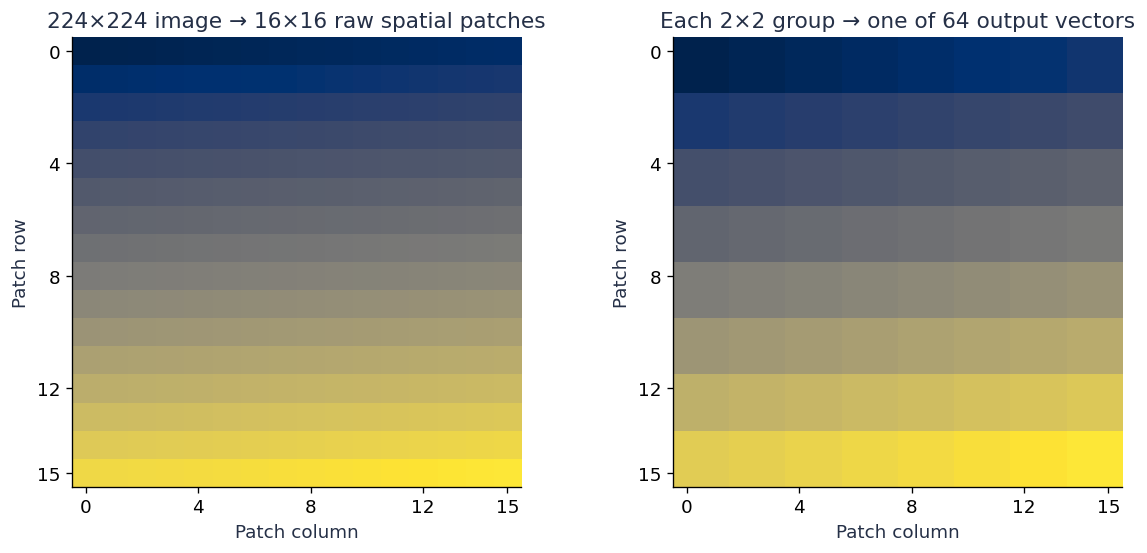

Before merging: (256,1280); grouped: (64,5120); projected: (64,2048)
This colored grid illustrates grouping, not learned visual features.


In [4]:
patch_ids=np.arange(16*16).reshape(16,16)
merge_groups=np.repeat(np.repeat(np.arange(64).reshape(8,8),2,axis=0),2,axis=1)
fig,axes=plt.subplots(1,2,figsize=(10,4.5),layout="constrained")
axes[0].imshow(patch_ids,cmap="cividis",interpolation="nearest")
axes[0].set(title="224×224 image → 16×16 raw spatial patches",xlabel="Patch column",ylabel="Patch row")
axes[1].imshow(merge_groups,cmap="cividis",interpolation="nearest")
axes[1].set(title="Each 2×2 group → one of 64 output vectors",xlabel="Patch column",ylabel="Patch row")
for ax in axes:
    ax.set_xticks([0,4,8,12,15]);ax.set_yticks([0,4,8,12,15])
finish_figure(fig,"vision_patches")
print("Before merging: (256,1280); grouped: (64,5120); projected: (64,2048)")
print("This colored grid illustrates grouping, not learned visual features.")

<a id="component-4"></a>

### 2.4 TMRoPE: connect position with space and time

#### Why token order is insufficient

At one video frame per second and four frames per second, the same frame-index difference represents different durations. Audio produces approximately 25 final representations per second. A common time coordinate can relate the streams despite their different sampling rates.

There are two operations: interleave features in time chunks, and assign coordinates reflecting time/space. Neither operation replaces the other.

To understand the position mechanism, begin with ordinary text positions, then add the extra coordinates. The goal is not to attach a timestamp to the final answer. It is to change how attention compares input features, so relative location and time can affect what attends to what.

#### Start with ordinary RoPE

For a channel pair and position p:

$$R(p\omega)=
\begin{pmatrix}\cos(p\omega)&-\sin(p\omega)\\
\sin(p\omega)&\cos(p\omega)\end{pmatrix},
\quad q'_p=R(p\omega)q_p,\quad k'_r=R(r\omega)k_r.$$

Therefore:

$$ (q'_p)^\top k'_r=q_p^\top R((r-p)\omega)k_r. $$

Here q_p and k_r are a query and key channel pair at positions p and r. The frequency omega determines how quickly their angles change as position advances. R is a two-dimensional rotation matrix, and the transpose symbol means exchanging matrix rows and columns. Queries and keys use the same rotation rule; subtracting their angles makes their relative positions appear in their dot product.

As a small example, choose omega=pi/2. A query vector (1,0) at position 1 becomes (0,1); a key (1,0) at position 2 becomes (-1,0). Their dot product becomes zero even though the original vectors were identical. The rotation has supplied positional information without changing either vector's length. Real attention heads use many such pairs with different frequencies.

The dot product depends on relative position through an angle difference. Rotations also preserve vector norm. Different channel pairs use frequencies such as theta raised to -2j/d_head.

HF pairs first-half and second-half channels using rotate_half. That is equivalent to two-dimensional rotations after a permutation. Comparing it with an adjacent-pair implementation requires matching the layout.

#### Split rotary channels across three coordinates

Each token gets (t,h,w) coordinates:

$$ {\rm TMRoPE}(q;t,h,w)=R_t(t)q_t\oplus R_h(h)q_h\oplus R_w(w)q_w. $$

The subscripts t, h, and w mean temporal, height, and width channel sections. The vector q is split into those sections; each section rotates using its own coordinate. The symbol ⊕ means combining channel sections. This is a conceptual teaching equation; the exact channel layout is in the source.

Thinker's mrope_section is [16,24,24], summing to half its 128-dimensional head. In [apply_multimodal_rotary_pos_emb](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1407–1449), Python list repetition by 2 gives [16,24,24,16,24,24]. It does not independently double each entry. Temporal/height/width cosine and sine values are selected section by section.

[Qwen2_5OmniRotaryEmbedding.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1391–1404) produces cosine/sine tensors shaped (3,B,L,d_head). The application function selects sections and broadcasts them over attention heads, then rotates queries and keys.

#### Modality conventions

| Modality | Coordinate convention |
|---|---|
| Text | (p,p,p), reducing to ordinary RoPE |
| Audio | The same increasing coordinate on all axes, about 40 ms per step |
| Image | Constant temporal coordinate; varying merged-grid height/width |
| Video | Time coordinates derived from seconds; varying spatial coordinates |

With 25 position IDs per second, relative video time s becomes approximately floor(25s). One-second grid spacing gives 0,25,50,…; two-second spacing gives 0,50,100,… . Integer conversion and sequence offsets follow the code.

For a tiny 2×2 merged image grid, the coordinates can be (0,0,0), (0,0,1), (0,1,0), and (0,1,1), before sequence offsets. All four share an image time, but retain distinct row/column addresses. A video grid at 2 seconds can use temporal ID 50 on the same 25-ID-per-second scale as audio. This makes physical time comparable even though that frame contributes several spatial tokens.

“Absolute time” here means clip-relative physical time with a sequence offset, not wall-clock time. A subsequent segment starts after the preceding maximum coordinate. It does not necessarily start after the number of preceding flattened tokens.

#### Interleaving and position construction

[Qwen2_5OmniProcessor.replace_multimodal_special_tokens](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py) (lines 210–278) places visual placeholders before audio placeholders within each two-second chunk. [Qwen2_5OmniPreTrainedModelForConditionalGeneration.get_rope_index](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 262–546) assigns positions in that same order.

Read its branches in increasing complexity: text only; standalone audio; image; video without audio; video with audio. Then examine rope_deltas, which makes position bookkeeping compatible with cached generation.

Look closely at start/end markers, removed padding, max()+1 offsets, and helper calls. These are necessary to implement the conceptual formula correctly.

A system using variable frame rates must preserve timing through media preparation. Position encoding cannot recover timestamps that a loader discarded.

#### Paper assignment and comprehension check

[Paper §2.2, PDF pp. 4](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). and Figure 3 are the main assignment. Compute a tiny image/video grid, then return to the figure. The paper explains TMRoPE mostly in prose and diagrams; the equations here make that account explicit.

**Check.** Must a text coordinate after 64 image tokens advance by 64?

**Answer.** No. The code advances from the maximum spatial/temporal coordinate plus one, including control-token bookkeeping.


The demonstration checks that equal coordinates on all three axes recover text RoPE and that rotations preserve vector norms. Its timeline then shows the intended audio/video arrangement; the note after the demonstration separates a historical implementation issue from that intended design.



![Original paper Figure 3](sources/paper/tex/figures/ATMRoPE.png)

Figure 3, Qwen Team, *Qwen2.5-Omni Technical Report* v1, reproduced under CC BY 4.0. Use the explanation above to interpret the original diagram.


2×2 merged image coordinates, rows t/h/w:
 [[0 0 0 0]
 [0 0 1 1]
 [0 1 0 1]]


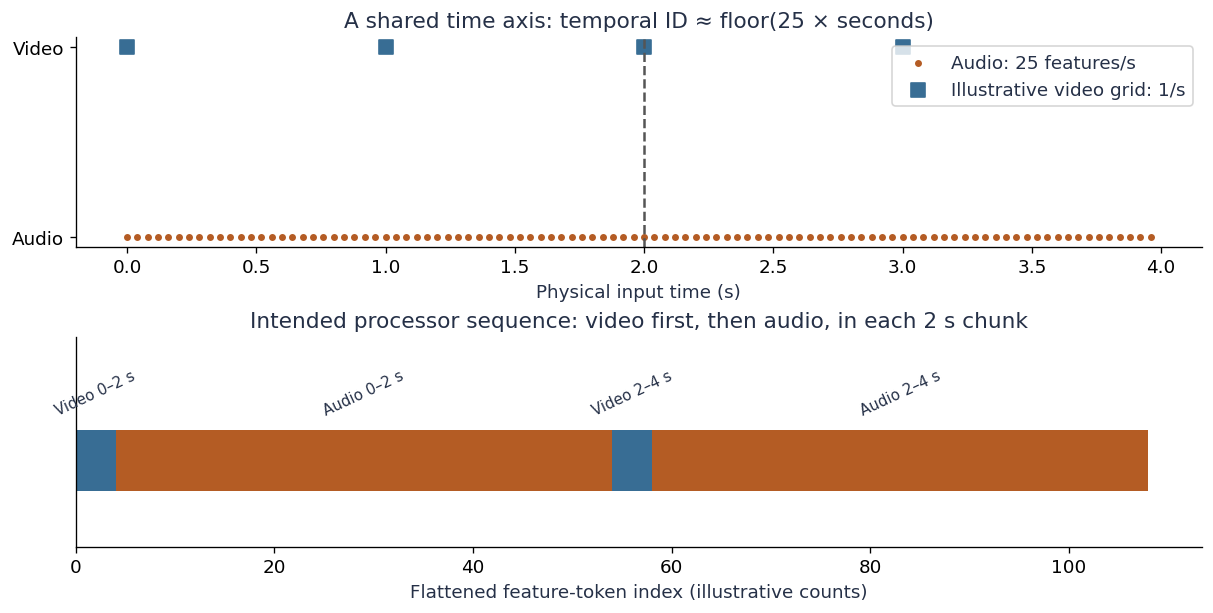

**Actual archived-HF check:** intended video coordinates [2, 52]; observed [2, 48]. See the implementation note below; the timeline illustrates intended design.

In [5]:
def rotate_half_np(x):
    half=x.shape[-1]//2
    return np.concatenate([-x[...,half:],x[...,:half]],axis=-1)

def rotary_np(q,position_ids,sections=(16,24,24),theta=1e6):
    # q: (sequence, head_dim); IDs: (3, sequence), split-half HF layout.
    dim=q.shape[-1]
    inv=theta**(-np.arange(0,dim,2)/dim)
    frequencies=position_ids[...,None]*inv[None,None,:]
    angles=np.concatenate([frequencies,frequencies],axis=-1)
    cuts=np.cumsum(sections*2)[:-1]
    pieces=np.split(angles,cuts,axis=-1)
    selected=np.concatenate([piece[i%3] for i,piece in enumerate(pieces)],axis=-1)
    return q*np.cos(selected)+rotate_half_np(q)*np.sin(selected)

q=rng.normal(size=(6,128))
text_ids=np.tile(np.arange(6),(3,1))
rotated=rotary_np(q,text_ids)
inv=1e6**(-np.arange(0,128,2)/128)
ordinary_angles=np.concatenate([np.arange(6)[:,None]*inv]*2,axis=-1)
ordinary=q*np.cos(ordinary_angles)+rotate_half_np(q)*np.sin(ordinary_angles)
results["tmrope_text_matches_rope"]=bool(np.allclose(rotated,ordinary))
results["rope_norm_error"]=float(np.max(np.abs(np.linalg.norm(q,axis=-1)-np.linalg.norm(rotated,axis=-1))))
assert results["tmrope_text_matches_rope"] and results["rope_norm_error"]<1e-10
tiny_grid=np.array([[0,0,0,0],[0,0,1,1],[0,1,0,1]])
print("2×2 merged image coordinates, rows t/h/w:\n",tiny_grid)
audio_times=np.arange(100)/25
video_times=np.array([0,1,2,3.0])
fig,axes=plt.subplots(2,1,figsize=(10,5),layout="constrained")
axes[0].scatter(audio_times,np.zeros_like(audio_times),s=10,color=COLORS["audio"],label="Audio: 25 features/s")
axes[0].scatter(video_times,np.ones_like(video_times),marker="s",s=80,color=COLORS["vision"],label="Illustrative video grid: 1/s")
axes[0].axvline(2,color="#555",ls="--")
axes[0].set(yticks=[0,1],yticklabels=["Audio","Video"],xlabel="Physical input time (s)",
            title="A shared time axis: temporal ID ≈ floor(25 × seconds)")
axes[0].legend(loc="upper right")
segments=[("Video 0–2 s",4,COLORS["vision"]),("Audio 0–2 s",50,COLORS["audio"]),
          ("Video 2–4 s",4,COLORS["vision"]),("Audio 2–4 s",50,COLORS["audio"])]
offset=0
for label,width,color in segments:
    axes[1].barh(0,width,left=offset,color=color,height=.5)
    axes[1].text(offset+width/2,.37,label,ha="center",fontsize=9,rotation=25)
    offset+=width
axes[1].set(ylim=(-.7,1),yticks=[],xlabel="Flattened feature-token index (illustrative counts)",
            title="Intended processor sequence: video first, then audio, in each 2 s chunk")
finish_figure(fig,"time_alignment")
hf_checks=json.loads((ROOT/"hf_mechanism_checks.json").read_text())
display(Markdown("**Actual archived-HF check:** intended video coordinates " +
                 str(hf_checks["audiovisual_expected_temporal_positions"]) + "; observed " +
                 str(hf_checks["audiovisual_actual_temporal_positions"]) +
                 ". See the implementation note below; the timeline illustrates intended design."))

#### Implementation note: a discrepancy in this historical snapshot

The processor's chunk helper receives a one-dimensional time-index array. The model's similarly named helper receives a tensor shaped (3,N), but loops while i is less than len(token_indices), which is 3 rather than N. This is a real snapshot-specific implementation issue, not the intended TMRoPE algorithm.

The included weight-free check executes the archived function bodies. For 100 audio positions and chunk size 50, the processor returns two chunks, while the model helper returns one. On a synthetic four-second audiovisual sequence, the first tokens of two visual grids receive temporal coordinates [2,48], whereas the intended chunk ordering gives [2,52]. A visual grid with only two tokens can also trigger an IndexError.

These observations are limited to the pinned historical commit. The archived upstream files remain byte-identical; this guide does not silently patch them or assert that every later Transformers release has the same behavior. The small correct-coordinate examples below teach the paper's design. The source-check results separately expose the observed implementation discrepancy.

Read [Qwen2_5OmniPreTrainedModelForConditionalGeneration.get_chunked_index](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 226–260) beside [Qwen2_5OmniProcessor.get_chunked_index](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py) (lines 280–311), then inspect the saved check results. This is why comparing shapes and execution with the paper is valuable.



**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)
- [sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py)


<a id="component-5"></a>

### 2.5 Thinker: reason over the shared sequence

Thinker is the point where the separate input paths become one reasoning context. The earlier components do not independently produce the final answer: they provide vectors that Thinker's language-model layers can compare. In our example, answering what the speaker meant may require attending to both the audio and the red bowl.

The checkpoint table below is read directly from config.json. Thinker's text backbone is 2,048 wide with 36 layers, 16 query heads, and 2 KV heads. Each head is 128 wide. Talker's input vectors also start at width 2,048, but its decoder is 896 wide. “3B” identifies the language-backbone scale; it does not mean all audio, vision, speech, and reconstruction modules together total exactly three billion parameters. The demonstration calculates the language-backbone count separately and draws the actual component boundaries.



| Component | Width | Layers | Q / KV heads |
|---|---:|---:|---:|
| Thinker text | 2048 | 36 | 16 / 2 |
| Audio encoder | 1280 → 2048 | 32 | 20 / full |
| Vision encoder | 1280 → 2048 | 32 | 16 / full |
| Talker | 2048 → 896 | 24 | 14 / 2 |

Backbone parameter calculation (untied input/output embeddings): 3,397,103,616
This excludes audio/vision encoders, Talker, and Token2Wav.


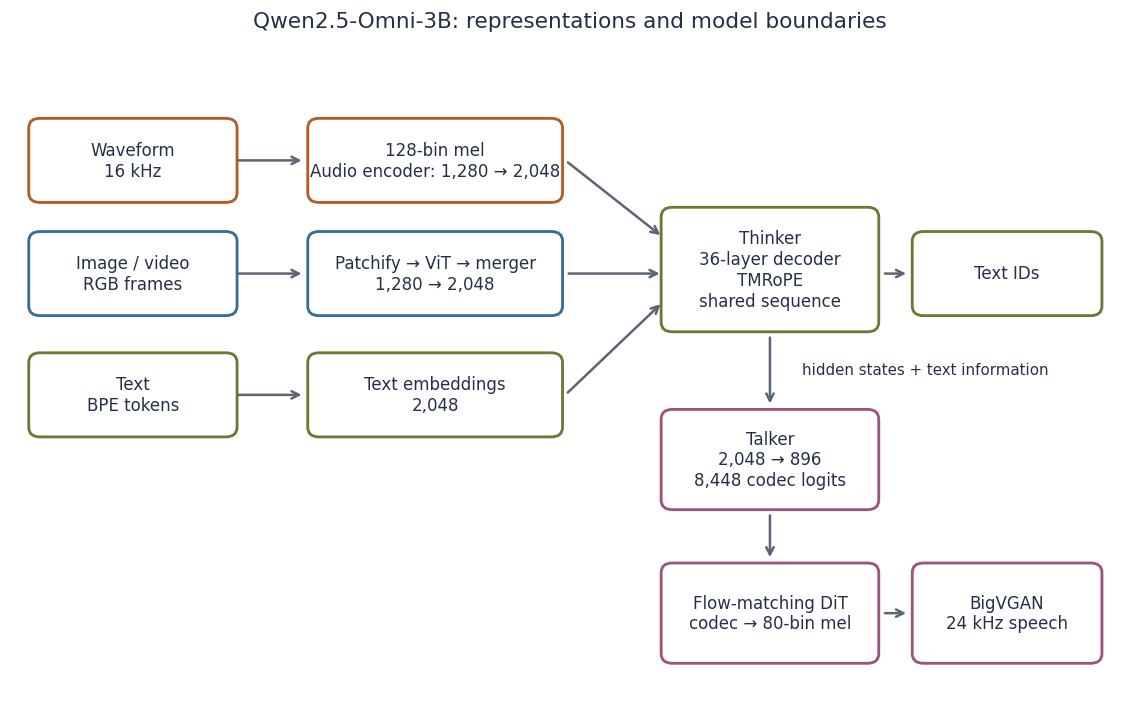

In [6]:
text_cfg = config["thinker_config"]["text_config"]
audio_cfg = config["thinker_config"]["audio_config"]
vision_cfg = config["thinker_config"]["vision_config"]
talk_cfg = config["talker_config"]
display(Markdown(
    "| Component | Width | Layers | Q / KV heads |\n|---|---:|---:|---:|\n"
    f"| Thinker text | {text_cfg['hidden_size']} | {text_cfg['num_hidden_layers']} | "
    f"{text_cfg['num_attention_heads']} / {text_cfg['num_key_value_heads']} |\n"
    f"| Audio encoder | {audio_cfg['d_model']} → {audio_cfg['output_dim']} | "
    f"{audio_cfg['encoder_layers']} | {audio_cfg['encoder_attention_heads']} / full |\n"
    f"| Vision encoder | {vision_cfg['hidden_size']} → {vision_cfg['out_hidden_size']} | "
    f"{vision_cfg['depth']} | {vision_cfg['num_heads']} / full |\n"
    f"| Talker | {talk_cfg['embedding_size']} → {talk_cfg['hidden_size']} | "
    f"{talk_cfg['num_hidden_layers']} | {talk_cfg['num_attention_heads']} / {talk_cfg['num_key_value_heads']} |"))
d = text_cfg["hidden_size"]
f = text_cfg["intermediate_size"]
kv_width = text_cfg["num_key_value_heads"] * (d // text_cfg["num_attention_heads"])
per_layer = 2*d*d + 2*d*kv_width + 3*d*f + 2*d + d + 2*kv_width
backbone_parameters = text_cfg["num_hidden_layers"] * per_layer + d + 2*text_cfg["vocab_size"]*d
print(f"Backbone parameter calculation (untied input/output embeddings): {backbone_parameters:,}")
print("This excludes audio/vision encoders, Talker, and Token2Wav.")

fig, ax = plt.subplots(figsize=(12,7))
ax.set(xlim=(0,12), ylim=(0,8))
ax.axis("off")
def box(x,y,w,h,label,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.12",
                              facecolor="white",edgecolor=color,linewidth=1.7))
    ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=10)
def arrow(a,b,label=None):
    ax.annotate("",xy=b,xytext=a,arrowprops=dict(arrowstyle="->",color="#5b6574",lw=1.5))
    if label:
        ax.text((a[0]+b[0])/2,(a[1]+b[1])/2+0.16,label,ha="center",fontsize=9)
box(.3,6.2,2.0,.8,"Waveform\n16 kHz",COLORS["audio"])
box(3.3,6.2,2.5,.8,"128-bin mel\nAudio encoder: 1,280 → 2,048",COLORS["audio"])
box(.3,4.8,2.0,.8,"Image / video\nRGB frames",COLORS["vision"])
box(3.3,4.8,2.5,.8,"Patchify → ViT → merger\n1,280 → 2,048",COLORS["vision"])
box(.3,3.3,2.0,.8,"Text\nBPE tokens",COLORS["text"])
box(3.3,3.3,2.5,.8,"Text embeddings\n2,048",COLORS["text"])
box(7.1,4.6,2.1,1.3,"Thinker\n36-layer decoder\nTMRoPE\nshared sequence",COLORS["text"])
box(9.8,4.8,1.8,.8,"Text IDs",COLORS["text"])
box(7.1,2.4,2.1,1.0,"Talker\n2,048 → 896\n8,448 codec logits",COLORS["speech"])
box(7.1,.5,2.1,1.0,"Flow-matching DiT\ncodec → 80-bin mel",COLORS["speech"])
box(9.8,.5,1.8,1.0,"BigVGAN\n24 kHz speech",COLORS["speech"])
for a,b in [((2.4,6.6),(3.15,6.6)),((2.4,5.2),(3.15,5.2)),((2.4,3.7),(3.15,3.7)),
            ((5.95,6.6),(7.0,5.65)),((5.95,5.2),(7.0,5.2)),((5.95,3.7),(7.0,4.85)),
            ((9.35,5.2),(9.65,5.2)),((8.15,4.45),(8.15,3.55)),
            ((8.15,2.25),(8.15,1.65)),((9.35,1),(9.65,1))]:
    arrow(a,b)
ax.text(8.5,3.95,"hidden states + text information",fontsize=9)
ax.set_title("Qwen2.5-Omni-3B: representations and model boundaries",pad=12)
finish_figure(fig,"architecture")

#### Follow one forward pass

[Qwen2_5OmniThinkerForConditionalGeneration.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2317–2507) first derives valid audio lengths and packs audio features. It computes position IDs on prefill, or derives continuation positions from cache position and rope_deltas.

Next it obtains text embeddings shaped (B,L,2048). On prefill, the audio tower and vision encoder return feature matrices of the same final width. Boolean masks identify audio/image/video token locations, and masked_scatter replaces the corresponding embedding elements.

The central operation is conceptually:

$$e_i=\begin{cases}
E_{\rm text}(x_i),&\text{text/control position},\\
f_{\rm audio}(X)_j,&\text{audio placeholder},\\
f_{\rm vision}(I)_j,&\text{visual placeholder}.
\end{cases}$$

The cases say which vector occupies position i. E_text is the learned text embedding table; x_i is a text/control token ID. The functions f_audio and f_vision denote the corresponding encoders, and j selects the matching media vector. B is batch size and L is the expanded input sequence length. All three cases must have the same final width of 2,048 to form one tensor.

The feature index j follows the processor's ordering. This is input fusion into a shared sequence; it is not a separate decoder cross-attention layer to every modality.

The function then calls the text Transformer, applies a language head, and optionally computes loss. The head returns logits: one raw score per possible output token. Softmax converts scores into probabilities before token selection or loss calculation. During single-token cached decoding it avoids repeatedly encoding the original media.

#### Attention shapes and grouped-query attention

[Qwen2_5OmniAttention.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1497–1561) maps hidden states into queries, keys, and values. For this Thinker:

- Queries: (B,16,L,128).
- Keys and values before repetition: (B,2,L,128).
- Each KV head is shared by 8 query heads.

After TMRoPE and cache update, repeat_kv makes keys/values compatible with the 16 query heads. The attention computation is:

$$A={\rm softmax}\left(\frac{Q'K'^\top}{\sqrt{128}}+M\right),\qquad O=AV.$$

Q' and K' are queries and keys after position rotation; V contains the values to be combined. Each entry of Q'K'^T scores one query/key pair. Dividing by the square root of head width keeps scores from growing simply because there are more channels. Softmax turns the permitted scores into weights that sum to one; AV forms a weighted average of value vectors. The mask M prevents reading positions that should not be available.

For intuition, suppose two permitted positions have scores 0 and log(3). Softmax gives weights 1/4 and 3/4. If their scalar values are 2 and 10, the attention output is 0.25×2+0.75×10=8. Real heads perform this operation on vectors, and the model learns the query/key/value projections.

M masks future positions and padding. Eager attention uses an additive mask with large negative masked values; boolean masks in PyTorch SDPA have different conventions, so inspect the backend rather than copying a mask indiscriminately.

The output is combined across heads and projected back to width 2,048. [Qwen2_5OmniDecoderLayer.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 1803–1868) wraps attention and an MLP with residual paths and normalization.

Grouped-query attention reduces the KV cache compared with storing 16 independent KV heads. An approximate cache element count for B sequences of length L over N layers is:

$$2BNLH_{\rm KV}d_{\rm head}.$$

H_KV is the number of key/value heads, d_head is each head’s width, and N is the number of layers. B and L again mean batch size and cached sequence length. The leading 2 represents K and V. This excludes weights, activations, and other modules; it is not a complete GPU-memory estimate.

#### Prefill versus decoding

Prefill processes the expanded prompt. Decoding processes a new token while reusing prior K/V states. [Qwen2_5OmniThinkerForConditionalGeneration.prepare_inputs_for_generation](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2509–2553) slices inputs and stops resending media features after prefill. The underlying GenerationMixin handles the autoregressive loop and sampling.

TMRoPE coordinates can differ from a flattened token counter, so continuation uses rope_deltas. Dropping that offset while retaining the KV cache can create inconsistent positions.

#### Training and next-token loss

With prompt/context X and answer Y:

$$p_\theta(Y\mid X)=\prod_{j=1}^{|Y|}
p_\theta(y_j\mid X,y_{<j}),\qquad
\mathcal L_{\rm CE}=-\sum_{j\in\mathcal S}\log p_\theta(y_j\mid X,y_{<j}).$$

Here theta denotes the model parameters; Y is the answer token sequence and X the input context. The product expresses generating one token after another. The negative sum of log-probabilities is the cross-entropy objective: it penalizes assigning low probability to the correct next token. For a single target token, probability 0.8 gives loss about 0.223, while probability 0.2 gives about 1.609. During training, gradient updates encourage the correct token to receive more probability.

The sum above shows the objective before reduction. The HF utility normally averages valid token losses; when num_items_in_batch is supplied, it divides the summed loss by that count. The supervised-position set S excludes labels marked -100. Teacher forcing supplies previous ground-truth tokens. The loss implementation shifts predictions and labels for next-token alignment. The precise dataset labeling policy is a training-data decision, not something to infer merely from the model forward pass.

[Qwen2_5OmniThinkerForConditionalGeneration.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2317–2507) delegates to the configured loss function; [ForCausalLMLoss](sources/transformers/src/transformers/loss/loss_utils.py) (lines 41–64) shows the shift and how -100 labels are ignored. Greedy decoding chooses argmax logits; sampling draws from a transformed distribution. Neither changes the trained architecture.

The attention demonstration compares processing a complete synthetic sequence with processing its continuation using cached keys/values. The outputs should agree up to numerical precision. This illustrates why caching can avoid repeating old computations while preserving the causal attention result; it does not measure the pretrained model's answers or runtime.

#### Paper assignment

[Paper §2.1, PDF pp. 3](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=3). identifies the decoder and encoders. [Paper §2.3, PDF pp. 4–5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). explains text generation. The paper assumes standard language-model machinery; the attention and caching details are most directly learned from the source.

**Check.** Are multimodal features re-encoded once for every generated word?

**Answer.** Not in this cached path. They are inserted during prefill; decoding reuses the resulting cache.


**Additional implementation reading:** [Qwen2_5OmniForConditionalGeneration.__init__](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4362–4370).


**Original files for this section:**

- [sources/transformers/src/transformers/loss/loss_utils.py](sources/transformers/src/transformers/loss/loss_utils.py)
- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)


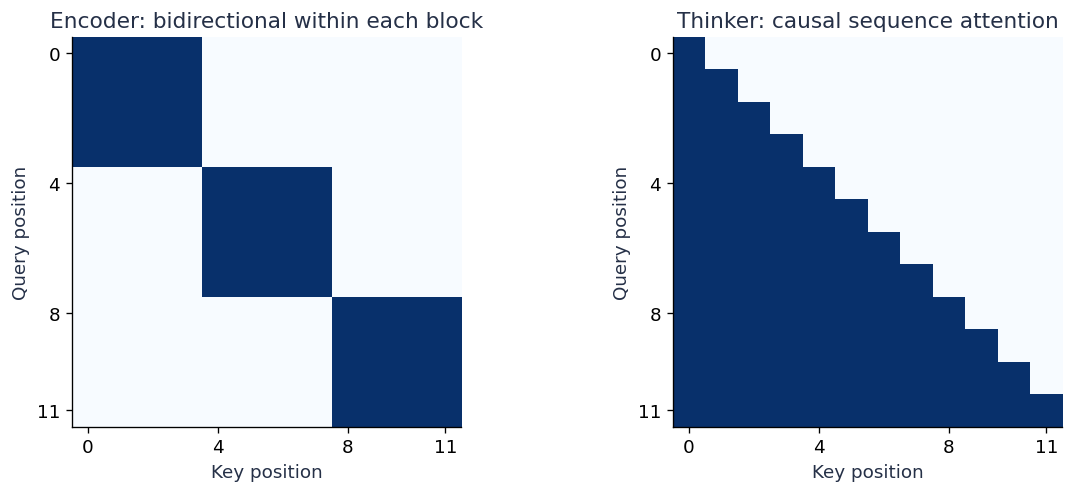

Synthetic cached/full attention max error: 4.163336342344337e-16
Mask illustration uses 4 positions/block, not the real audio block length.


In [7]:
length,dim=12,8
Q,K,V=[rng.normal(size=(length,dim)) for _ in range(3)]
def softmax(x):
    ex=np.exp(x-x.max(axis=-1,keepdims=True))
    return ex/ex.sum(axis=-1,keepdims=True)
causal=np.tri(length,dtype=bool)
scores=Q@K.T/np.sqrt(dim)
full=softmax(np.where(causal,scores,-np.inf))@V
cached=[]
for i in range(length):
    cached.append(softmax(Q[i:i+1]@K[:i+1].T/np.sqrt(dim))@V[:i+1])
cached=np.concatenate(cached,axis=0)
results["cached_attention_error"]=float(np.max(np.abs(full-cached)))
assert results["cached_attention_error"]<1e-10
block_ids=np.arange(length)//4
blockwise=block_ids[:,None]==block_ids[None,:]
fig,axes=plt.subplots(1,2,figsize=(10,4),layout="constrained")
for ax,mask,title in zip(axes,[blockwise,causal],["Encoder: bidirectional within each block","Thinker: causal sequence attention"]):
    ax.imshow(mask,origin="upper",cmap="Blues",vmin=0,vmax=1)
    ax.set(title=title,xlabel="Key position",ylabel="Query position",xticks=[0,4,8,11],yticks=[0,4,8,11])
finish_figure(fig,"attention_masks")
print("Synthetic cached/full attention max error:",results["cached_attention_error"])
print("Mask illustration uses 4 positions/block, not the real audio block length.")

<a id="component-6"></a>

### 2.6 Talker: turn text and context into speech codes

#### Why both hidden states and text information?

After Thinker has decided what to say, the system still needs an acoustic sequence. A word can occupy several sound frames; some context should affect emphasis or pauses. Talker addresses that different output problem. A speech code is an integer identifying a learned acoustic symbol, rather than a written character or waveform sample. Token2Wav interprets those symbols; the next section explains the codec background. Hidden states carry contextual meaning, style, and information useful for anticipating prosody. But semantic similarity does not uniquely specify pronunciation. The paper therefore supplies Talker with both Thinker representations and sampled-text information.

This is richer than passing a completed plain-text string to an unrelated TTS system. However, whether the released wrapper actually runs modules concurrently is a separate implementation question.

#### Read the orchestration before the decoder

In [Qwen2_5OmniForConditionalGeneration.generate](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4440–4630), identify:

1. The full call to Thinker.generate, requesting hidden states when speech is needed.
2. Collection of embedding-layer and final-layer states.
3. Construction of Talker's context, reply features, speaker token, and codec markers.
4. The call to Talker.generate.
5. Removal of prefix/terminal codec tokens and the call to Token2Wav.

Each generation step returns a tuple of layer states. The first step includes the prompt/prefill; later steps correspond to continuation tokens. Therefore the sequence and hidden-state indices require care: the final hidden state predicts a next token, and its associated embedding input is not interchangeable with the embedding of every returned output ID.

The wrapper sums selected final-layer representations and embedding-layer representations. It separately constructs speaker/text boundary embeddings and reply continuation features. Read those slices rather than assuming a simplistic one-word-to-one-audio-token alignment.

#### The Talker input projection

[Qwen2_5OmniTalkerForConditionalGeneration.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2938–3070) combines a codec embedding with the next conditioning vector during continuation, then applies the Thinker-to-Talker projection:

$$u_j=E_{\rm codec}(c_{j-1})+r_j,\qquad
z_j=W_{\rm proj}u_j+b_{\rm proj}.$$

r_j denotes the conditioning vector prepared by the wrapper, including its text/hidden-state and boundary conventions. This is an explanatory expression for the continuation branch, not a complete formula for every prefill position.

In the formula, c_(j-1) is the previously generated codec ID, E_codec looks up its embedding, and j indexes the current codec-generation step. Adding r_j mixes this acoustic history with the prepared conditioning. W_proj is a learned 896×2048 matrix in the mathematical column-vector convention, and b_proj has 896 entries. It converts the sum into the decoder's working width.

A smaller example makes the operation visible. If the previous codec embedding is (1,0) and the conditioning vector is (0,2), their sum is (1,2). A projection row (3,4), with zero bias, maps that to 11. The real projection produces 896 values, not one. This example explains addition and projection; it is not a learned speech predictor.

For this checkpoint, u_j is width 2,048 and z_j width 896. The codec embedding table uses the input embedding width; the codec output head maps 896-dimensional Transformer states to 8,448 logits. The codec vocabulary includes reserved IDs, so the head width is not identical to the number of ordinary audio codes.

Follow [Qwen2_5OmniTalkerModel.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2631–2746) after projection. It runs a causal decoder with its own KV cache. Codec generation is autoregressive:

$$p_\phi(C\mid R,X)=\prod_jp_\phi(c_j\mid c_{<j},R,X).$$

C denotes the full codec sequence, R the prepared Thinker conditioning, X other supplied context, and phi the Talker parameters. The product says that the next speech code depends on previous codes and the conditioning. This factorization expresses conditioning. It does not claim that every text token aligns to exactly one codec token, or that a specific joint loss was implemented in this inference port.

#### “Dual-track” in the paper versus released code

[Paper §2.3, PDF pp. 4–5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). describes the two-track relationship between text and speech and says that word/timestamp alignment is unnecessary. In this HF snapshot, Thinker supplies the text information, while Talker's exposed prediction head is a **codec head**. Do not invent an additional released text-output head simply because the paper uses the phrase dual-track.

The Talker forward method initializes loss to None. Its docstring mentions labels, but its actual signature and body do not implement a Talker training loss. A docstring alone is not evidence of a released training pipeline.

#### Speaker information and termination

The wrapper looks up a speaker map containing a speaker-specific beginning token, conditioning vector, and reference mel. Text and codec start/end/padding tokens have distinct roles and vocabularies. EOS detection, maximum generated length, and removal of terminal codes prevent control tokens from being sent as ordinary speech content.

The released wrapper supports only batch size one when audio output is requested. Return shape also depends on return_audio: text-only returns IDs, whereas audio-enabled generation returns IDs and waveform.

#### Streaming distinction

The code awaits Thinker.generate before calling Talker.generate, and awaits the codec sequence before invoking Token2Wav. Thus this convenience wrapper does not demonstrate simultaneous end-to-end delivery of text and audio chunks. The architecture and receptive fields can support streaming-oriented designs while this public wrapper remains staged.

**Check.** Is a semantic hidden state sufficient to determine the exact spoken word?

**Answer.** Not necessarily. Meaning and phonetic identity differ. Text information helps disambiguate pronunciation, while hidden representations contribute contextual information.


**Reading and demonstration:** [Paper §2.3, PDF pp. 4–5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). Read the relationship between text representations and speech codes, then trace the wrapper and Talker forward functions linked above. The scaled demonstration below checks the addition/projection shapes and shows the actual staged wrapper order. Keep that call-order figure separate from the paper’s intended streaming behavior.


**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)


Scaled demonstration: (1, 3, 8) + codec (1, 3, 8) → (1, 3, 4)
Actual continuation dimensions: (B,1,2048) → projection → (B,1,896) → 8448 codec logits.
The random vectors illustrate the operation; they do not generate speech.


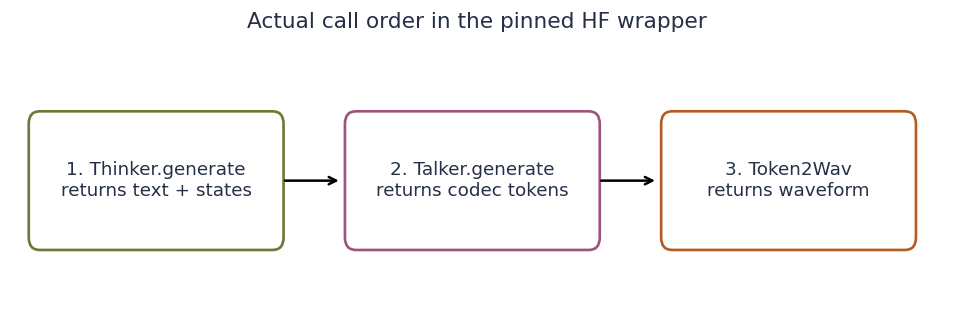

In [8]:
# Scaled dimensions make the addition/projection easy to inspect.
contextual=rng.normal(size=(1,3,8))
text_information=rng.normal(size=(1,3,8))
codec_embedding=rng.normal(size=(1,3,8))
conditioning=contextual+text_information
projection=rng.normal(size=(8,4))
talker_input=(conditioning+codec_embedding)@projection
print("Scaled demonstration:",conditioning.shape,"+ codec",codec_embedding.shape,"→",talker_input.shape)
print("Actual continuation dimensions: (B,1,2048) → projection → (B,1,896) → 8448 codec logits.")
print("The random vectors illustrate the operation; they do not generate speech.")
fig,ax=plt.subplots(figsize=(10,2.8))
ax.axis("off");ax.set(xlim=(0,10),ylim=(0,2.5))
for x,title,color in [(0.3,"1. Thinker.generate\nreturns text + states",COLORS["text"]),
                       (3.7,"2. Talker.generate\nreturns codec tokens",COLORS["speech"]),
                       (7.1,"3. Token2Wav\nreturns waveform",COLORS["audio"])]:
    ax.add_patch(FancyBboxPatch((x,.7),2.5,1.1,boxstyle="round,pad=.12",facecolor="white",edgecolor=color,lw=1.6))
    ax.text(x+1.25,1.25,title,ha="center",va="center")
for x in [2.9,6.3]:
    ax.annotate("",xy=(x+.65,1.25),xytext=(x,1.25),arrowprops=dict(arrowstyle="->",lw=1.5))
ax.set_title("Actual call order in the pinned HF wrapper",pad=14)
finish_figure(fig,"wrapper_order")

<a id="component-7"></a>

### 2.7 Token2Wav: turn speech codes into audible sound

Talker outputs integers, but a loudspeaker needs a rapidly sampled waveform. Token2Wav bridges that gap in two stages: first generate a time/frequency representation conditioned on the codes, then synthesize samples from it. This is a different job from recognizing the input recording or choosing the answer's words.

#### Keep three audio representations separate

1. Input audio uses 128-bin features and continuous encoder vectors.
2. Talker generates discrete codec IDs.
3. Token2Wav produces 80-bin mel features, then waveform samples.

The input and output mel dimensions differ. Their transforms and normalization also differ. Reusing the input Whisper features as output-vocoder conditioning would conflate separate interfaces.

#### What is a speech codec/tokenizer?

A learned audio tokenizer compresses acoustic information into discrete symbols. A generic vector-quantization explanation is:

$$h=f_{\rm enc}(x),\qquad
c=\arg\min_k\|h-e_k\|^2,\qquad \hat x=f_{\rm dec}(e_c).$$

In this background formula, x is a waveform segment, f_enc produces a continuous feature h, the codebook contains vectors e_k, and c selects the nearest one by squared Euclidean distance. The decoder f_dec reconstructs audio from the selected vector. A typical system learns an encoder, a table of representative vectors, and a decoder together; discretization gives a language-model-like predictor a finite set of symbols to choose from. Here e_k is a codebook vector. Reconstruction and codebook/commitment objectives are common ways to train such systems. **This is background intuition, not a disclosed exact architecture or objective for qwen-tts-tokenizer.** The Omni report names that tokenizer but does not fully specify its encoder and training recipe. This HF snapshot exposes codec-conditioned reconstruction rather than a complete raw-waveform tokenizer training implementation.

#### Flow matching: learn a velocity field

Read the archived [Flow Matching paper](sources/references/flow-matching-2210.02747v1.pdf) for the general framework. The intuition is to start with noise and repeatedly move it toward a plausible spectrogram, with the speech codes telling the network what to synthesize. A simple teaching path connects noise x_0 to a target mel sample x_1:

$$x_t=(1-t)x_0+tx_1,\qquad u_t=x_1-x_0,$$

$$\mathcal L_{\rm FM}=
\mathbb E_{t,x_0,x_1}\|v_\theta(x_t,t,c)-u_t\|^2.$$

t is interpolation time in [0,1], not audio time. c denotes codec and speaker conditioning. The network predicts a velocity with the same shape as the evolving mel tensor. Training samples random t and supervises the velocity. The subscript theta denotes the learned parameters, E means an average over training samples, and the squared norm sums prediction errors over mel/time entries. A velocity is a proposed change, not a waveform sample or codec ID.

For one scalar entry, take x_0=-1 and x_1=3. At t=0.25 the interpolated value is 0, and the target velocity is 4. A network predicting velocity 3 incurs squared error 1 on this entry. The real network predicts an entire 80-bin spectrogram's changes, conditioned on speech and speaker information.

This linear path/objective is a transparent example of conditional flow matching. The inference code alone does not establish Omni's exact training path, noise schedule, loss weighting, or complete data recipe.

During synthesis, solve:

$$\frac{dx_t}{dt}=v_\theta(x_t,t,c),\qquad x_0\sim\mathcal N(0,I).$$

The solver repeatedly predicts changes to the whole mel state. Flow matching is not the same operation as autoregressively choosing the next codec token.

#### Follow the DiT inputs

[Qwen2_5OmniToken2WavDiTModel.sample](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4224–4279) creates noise, sizes the output to codec length times repeats, creates time points, and integrates the ODE.

[DiTCodecEmbedding.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 3511–3517) embeds codec IDs and repeats them to the mel rate. repeats=2 means two mel frames per codec token. [DiTInputEmbedding.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 3480–3501) concatenates noisy mel, encoded reference-mel information, codec embeddings, and speaker conditioning, then projects them into the Transformer.

The reference-mel path uses an ECAPA-style time-delay network: temporal convolutions, residual/multiscale features, channel attention, and attentive statistics pooling summarize speaker-related information. Channel attention weights useful feature channels, while attentive pooling weights time positions and summarizes their statistics. This turns a variable-length reference into speaker-related conditioning. The released inference path does not disclose the full training objective for this conditioning encoder. That conditioning encoder is part of the waveform path; it is not Thinker's Whisper-derived audio tower.

[DiTDecoderLayer.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 3720–3741) uses timestep-conditioned normalization and gates:

$$\tilde h={\rm LN}(h)\odot(1+s(t))+b(t),\qquad
h_{\rm next}=h+g(t)\odot{\rm Attention}(\tilde h).$$

Here h is a hidden-state tensor, LN normalizes its channels, and the elementwise product symbol means multiplying corresponding entries. The functions s(t), b(t), and g(t) supply timestep-dependent scale, shift, and gate values. The gate controls how much the attention result changes the existing state. These s and b symbols are modulation values, not the later guidance scale. Additional modulation controls the MLP branch. The “DiT” name identifies a Transformer backbone that processes the evolving noisy representation with time conditioning; the sampler here follows a flow-matching ODE.

#### Guidance and numerical integration

The code combines conditional and null predictions:

$$v_{\rm guided}=v_{\rm cond}+s(v_{\rm cond}-v_{\rm null}).$$

This code's s is extra guidance beyond the conditional prediction, equivalent to a conventional null-plus-guidance expression with scale 1+s. The null path drops codec/audio/speaker conditions using the implementation's conventions.

[RungeKutta4ODESolver](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4072–4125) implements RK4. For step size h:

$$k_1=v(t,x),\quad k_2=v(t+h/2,x+hk_1/2),$$
$$k_3=v(t+h/2,x+hk_2/2),\quad k_4=v(t+h,x+hk_3),$$
$$x_{\rm next}=x+\frac h6(k_1+2k_2+2k_3+k_4).$$

Each k is a velocity estimate. RK4 probes the start, two midpoints, and the end of a step, then uses their weighted average. The step h here is a change in ODE time, distinct from the hidden tensor h above and from audio duration. For the constant velocity 4 in the scalar example, a step h=0.1 moves the state by 0.4; ten such steps move -1 to 3.

The demonstration uses the known constant velocity from noise to a synthetic target. The tiny final error checks integration arithmetic. It does not train a neural network or prove that an untrained model can recover real speech.

The code also transforms the time grid with a sway coefficient, redistributing integration points between the start and end of the trajectory. More time points generally cost more evaluations; a default num_steps value is not a benchmark of audio quality.



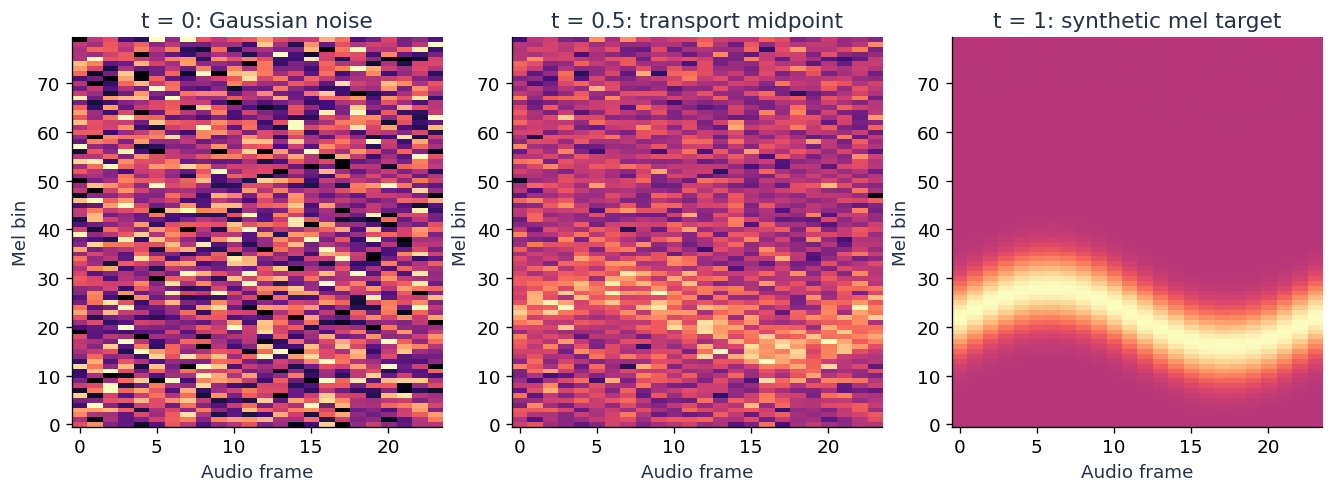

Oracle-path RK4 endpoint error: 1.5543122344752192e-15


In [9]:
noise=rng.normal(size=(80,24))
time_axis=np.linspace(0,1,24)
mel_axis=np.arange(80)[:,None]
target=np.exp(-((mel_axis-(22+6*np.sin(2*np.pi*time_axis)))/7)**2)*2
velocity=target-noise
state=noise.copy()
trajectory=[state.copy()]
# Oracle linear-path velocity: no neural network is trained in this demonstration.
for _ in range(10):
    h=.1
    k1=velocity;k2=velocity;k3=velocity;k4=velocity
    state=state+h*(k1+2*k2+2*k3+k4)/6
    trajectory.append(state.copy())
results["flow_endpoint_error"]=float(np.max(np.abs(state-target)))
assert results["flow_endpoint_error"]<1e-10
fig,axes=plt.subplots(1,3,figsize=(11,4),layout="constrained")
for ax,array,title in zip(axes,[trajectory[0],trajectory[5],trajectory[-1]],["t = 0: Gaussian noise","t = 0.5: transport midpoint","t = 1: synthetic mel target"]):
    ax.imshow(array,origin="lower",aspect="auto",cmap="magma",vmin=-2,vmax=2)
    ax.set(title=title,xlabel="Audio frame",ylabel="Mel bin")
finish_figure(fig,"flow_matching")
print("Oracle-path RK4 endpoint error:",results["flow_endpoint_error"])

#### Streaming masks: inspect each layer

[Qwen2_5OmniToken2WavDiTModel._create_block_diff](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4165–4173) computes key-block minus query-block indices. [DiTDecoderLayer.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 3720–3741) allows attention within configured lookback/lookahead limits.

The defaults are block_size=24 mel positions, lookback at layers 0 and 20, and lookahead at layer 10. Most layers attend within the current block. Those cross-block layers compose into an attention dependency envelope extending up to two blocks backward and one forward, matching the paper's four-block account. It is not a direct four-block mask in every layer.

For example, a query in block 3 can ultimately depend on blocks 1 through 4 after the relevant layers compose. The following mask demonstration makes that dependency visible. It distinguishes an individual layer’s allowed connections from the network’s combined receptive field.

Finite lookahead requires waiting for some future codec information. It is streaming-compatible with bounded delay, not strictly causal with zero lookahead. Attention-mask bounds alone also do not establish that the entire speaker/reference-conditioning path is causal.



![Original paper Figure 4](sources/paper/tex/figures/attentionmask.png)

Figure 4, Qwen Team, *Qwen2.5-Omni Technical Report* v1, reproduced under CC BY 4.0. Use the explanation above to interpret the original diagram.


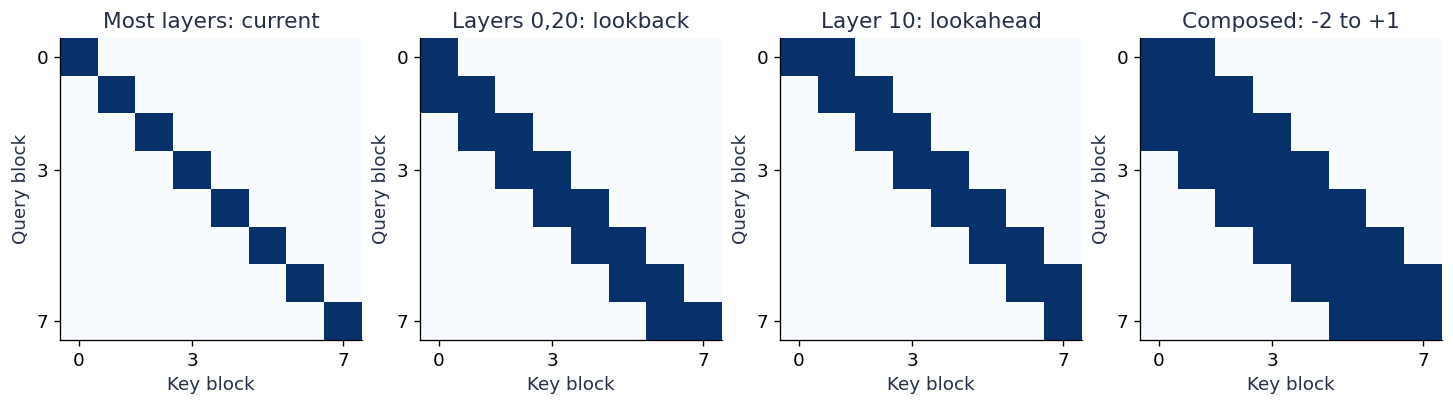

These are block-level attention dependencies. Other layers preserve within-block access; conditioning is separate.

In [10]:
blocks=np.arange(8)
diff=blocks[None,:]-blocks[:,None]
local=diff==0
back=(diff>=-1)&(diff<=0)
ahead=(diff>=0)&(diff<=1)
def compose(a,b):
    return (a.astype(int)@b.astype(int))>0
reach=compose(back,compose(ahead,back))
assert reach[3].nonzero()[0].tolist()==[1,2,3,4]
fig,axes=plt.subplots(1,4,figsize=(12,3.6),layout="constrained")
for ax,mask,title in zip(axes,[local,back,ahead,reach],["Most layers: current","Layers 0,20: lookback","Layer 10: lookahead","Composed: -2 to +1"]):
    ax.imshow(mask,cmap="Blues",vmin=0,vmax=1)
    ax.set(title=title,xlabel="Key block",ylabel="Query block",xticks=[0,3,7],yticks=[0,3,7])
finish_figure(fig,"dit_receptive_field")
display(Markdown("These are block-level attention dependencies. Other layers preserve within-block access; conditioning is separate."))

#### BigVGAN: reconstruct samples from mel

The mel spectrogram still is not playable audio: it describes energy in bands, without explicitly giving every waveform sample. A vocoder learns to produce a suitable waveform. The [BigVGAN paper](sources/references/bigvgan-2206.04658v1.pdf) describes a convolutional generator trained with adversarial, feature-matching, and reconstruction-related losses. Its generator upsamples mel features and uses periodic activations with anti-alias filtering to model waveform structure. Periodic activations help represent repeating waveform patterns; anti-alias filtering reduces unwanted frequency artifacts introduced around those nonlinear operations. This is background from the original vocoder, not a claim that Omni releases an identical training recipe.

[Qwen2_5OmniToken2WavBigVGANModel.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4054–4069) normalizes mel values, runs transposed convolutions and residual blocks, applies periodic/anti-aliased activations, and outputs clamped waveform samples. Its upsample rates multiply to 240. With the model card's 24 kHz output, this corresponds nominally to 100 mel frames per second and, with repeats=2, 50 codec tokens per second. For 50 codec tokens, repetition gives 100 mel frames, and nominal upsampling gives 24,000 waveform samples—about one second of output. Boundary handling follows the actual decoder. These output rates differ from the input audio encoder's 25 representations per second.

[Qwen2_5OmniToken2WavModel.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4312–4335) connects the sampler and vocoder. Notice that a local variable named generated_waveform inside the DiT sampler actually holds an intermediate mel-state trajectory; trace shapes rather than trusting names.

#### Paper assignment and check

[Paper §2.3, PDF pp. 4–5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). explains speech codes; [Paper §2.4, PDF pp. 5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=5). and Figure 4 explain streaming reconstruction. Read the original component papers for the theory omitted by the short report.

**Check.** Are ODE time t, video timestamps, and autoregressive codec indices the same coordinate?

**Answer.** No. ODE time indexes denoising/transport progress; video timestamps index physical input time; codec indices index generated speech symbols.


**What the output losses mean:** the original vocoder’s discriminator learns to distinguish real and generated waveform segments; the generator learns to make generated segments difficult to distinguish. Feature-matching losses also compare internal discriminator activations, and reconstruction-related terms encourage acoustic agreement with a reference. These explain how a convolutional generator can learn realistic audio, while the report’s unreleased full training recipe remains a separate limitation.


**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)


<a id="component-8"></a>

### 2.8 Training: teach the components to work together

So far we have followed inference: what happens when a trained model receives a request. Training asks a different question: how do the encoders, reasoning model, and speech modules learn to work together? Initialization provides useful starting capabilities; alignment connects their representations; joint training teaches the combined tasks; post-training improves conversational behavior and speech stability.

#### Pretraining stages

[Paper §3, PDF pp. 6](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=6). describes:

1. Initialize the LLM from Qwen2.5, the audio encoder from Whisper-large-v3, and use the Qwen2.5-VL vision encoder. Keep the LLM fixed while first training adapters, then encoders, to align features with the language space.
2. Unfreeze parameters and train with mixed text, image, video, audio, and audiovisual data. The report cites additional 800B image/video-related tokens, 300B audio-related tokens, and 100B audiovisual-related tokens. Treat these as reported family training quantities, not an independently reproduced accounting for the 3B checkpoint.
3. Extend training sequence length from 8,192 to 32,768 using longer audio/video and other inputs.

Freezing the LLM initially gives the encoders a stable target space. Joint training then allows the system to adapt across modalities. Longer-context training addresses a different problem: learning to use extended sequences.

These motivations are interpretations of the training schedule. They do not establish missing optimizer settings, learning rates, exact loss weights, or curriculum proportions.

#### Post-training Thinker and Talker

[Paper §4.1, PDF pp. 6](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=6). and [Paper §4.2, PDF pp. 6](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=6). describe ChatML instruction data containing pure-text and multimodal conversations.

[Paper §4.3, PDF pp. 7](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=7). describes Talker continuation training, preference optimization, and speaker fine-tuning. Next-token supervision teaches speech continuation; preferences improve generation stability; speaker tuning specializes voices. The report mentions timbre disentanglement but does not give enough detail to implement its full objective.

#### Explain DPO, the paper's Equation (1)

For input x, preferred speech sequence y_w, rejected speech sequence y_l, policy P_theta, reference policy P_ref, and scale beta:

$$\mathcal L_{\rm DPO}
=-\mathbb E_{(x,y_w,y_l)}
\log\sigma\left[
\beta\left(
\log\frac{P_\theta(y_w\mid x)}{P_{\rm ref}(y_w\mid x)}
-\log\frac{P_\theta(y_l\mid x)}{P_{\rm ref}(y_l\mid x)}
\right)\right].$$

The sigmoid sigma turns a real-valued preference score into a value between zero and one; the negative logarithm rewards making the preferred outcome more likely in that comparison. beta controls the scale of the reference-relative score. The expectation averages over prompt/preferred/rejected examples.

This is **Equation (1) in Omni §4.3**, on PDF page 7. Sequence log-probabilities are sums of autoregressive token log-probabilities:

$$\log P_\theta(y\mid x)=\sum_j\log P_\theta(y_j\mid x,y_{<j}).$$

Define the reference-relative margin:

$$m=\left[\log P_\theta(y_w\mid x)-\log P_{\rm ref}(y_w\mid x)\right]
-\left[\log P_\theta(y_l\mid x)-\log P_{\rm ref}(y_l\mid x)\right].$$

Then the pair loss is softplus(-beta m). If policy equals reference, m=0 and the loss is log 2. Increasing the preferred sequence's relative log-probability lowers the loss. A fixed reference anchors the comparison. For example, with beta=0.1, margin m=0 gives about 0.693 loss; margin m=5 gives about 0.474. The preferred sequence has improved relative to the rejected sequence and to the fixed reference. The demonstration plots that relationship rather than optimizing a real Talker.

The report constructs preferences using word-error rate and punctuation/pause errors. Lower loss does not by itself prove naturalness or identify the exact reward/data implementation. The original [DPO paper](sources/references/dpo-2305.18290v1.pdf) explains the objective's connection to preference-based policy optimization.

#### Paper and implementation reading

Thinker's forward path exposes a language-model loss. This inference port does not include the complete pretraining curriculum, speech-tokenizer training, preference-data construction, or a DPO trainer.

[Qwen2_5OmniTalkerForConditionalGeneration.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2938–3070) sets loss to None. Read [ForCausalLMLoss](sources/transformers/src/transformers/loss/loss_utils.py) (lines 41–64) for the available text next-token loss, rather than mistaking it for a speech DPO trainer. Therefore DPO has a paper/theory mapping here and an explicit **release gap**, not a fabricated pointer to an inference function presented as its trainer.

**Check.** Can a released forward pass alone reproduce the reported training?

**Answer.** No. You also need data, preprocessing/labeling, initialization details, objectives, schedules, and optimization settings, some of which are not fully released.


**Original files for this section:**

- [sources/transformers/src/transformers/loss/loss_utils.py](sources/transformers/src/transformers/loss/loss_utils.py)
- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)


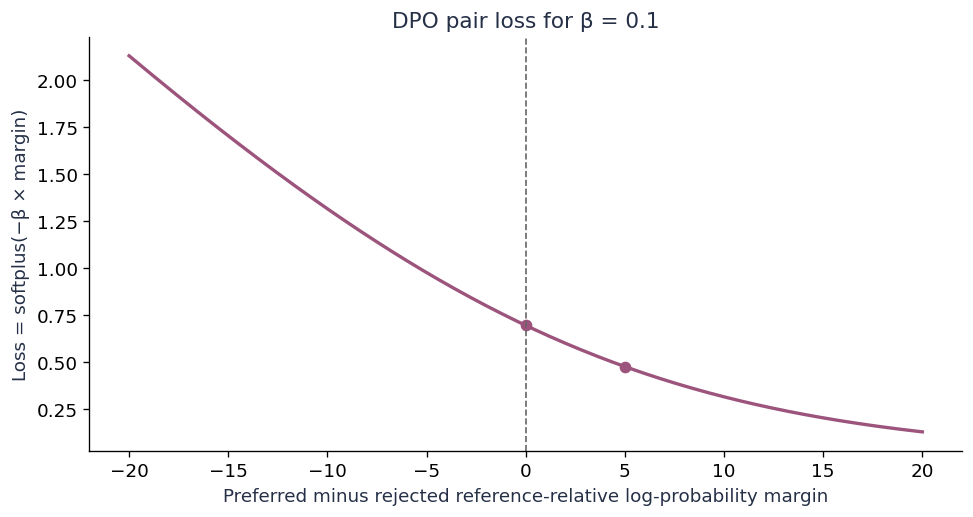

Equal-to-reference policy: 0.6931471805599453
Preferred margin +5: 0.4740769841801067


In [11]:
beta=.1
margins=np.linspace(-20,20,201)
losses=np.logaddexp(0,-beta*margins)
results["baseline_dpo_loss"]=float(np.logaddexp(0,0))
results["preferred_dpo_loss"]=float(np.logaddexp(0,-beta*5))
assert results["preferred_dpo_loss"]<results["baseline_dpo_loss"]
fig,ax=plt.subplots(figsize=(8,4.2),layout="constrained")
ax.plot(margins,losses,color=COLORS["speech"],lw=2)
ax.axvline(0,color="#666",ls="--",lw=1)
ax.scatter([0,5],[results["baseline_dpo_loss"],results["preferred_dpo_loss"]],color=COLORS["speech"])
ax.set(title="DPO pair loss for β = 0.1",xlabel="Preferred minus rejected reference-relative log-probability margin",
       ylabel="Loss = softplus(−β × margin)")
finish_figure(fig,"dpo_loss")
print("Equal-to-reference policy:",results["baseline_dpo_loss"])
print("Preferred margin +5:",results["preferred_dpo_loss"])

<a id="component-9"></a>

### 2.9 Complete walkthrough: connect the stages

Return to the cooking example from Part 1. To make the counts easy to follow, take one already resized 224×224 frame showing the red bowl, two seconds of audio, and a text question. This is a simplified image-plus-audio request; a true video repeats the visual grids over time. The walkthrough explains data flow, not an answer produced by downloaded weights.

**Prepare the request.** The chat template supplies roles and modality markers. The processor turns the frame into a patch grid (1,16,16) and the recording into 200 valid mel frames. It expands the image marker to 64 positions and the audio marker to 50 positions. The text question and control markers add their own positions. Read [Qwen2_5OmniProcessor.__call__](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py) (lines 106–208) and its placeholder-expansion helper to connect the user-facing message with those counts.

**Encode the media.** Vision starts with 256 raw patch vectors, attends over them, and merges them into 64 vectors of width 2,048. Audio applies convolutions, block attention, pooling, and projection to return 50 vectors of the same width. The numbers 64 and 50 are lengths; 2,048 is the width of every vector. This distinction explains why the two modalities can occupy the same language-model sequence despite having different rates.

| Boundary | Representation for this example | What changes here? |
|---|---|---|
| Prepared image | 256 patches, each with 1,176 pixel values | Pixels become patch inputs |
| Vision output | (64,2048) | Attention and learned merging produce model vectors |
| Prepared audio | (128,200), before any padding | Samples become time/frequency features |
| Audio output | (50,2048) | Encoding and downsampling produce model vectors |
| Thinker input | (1,L,2048) | 114 media locations are filled, alongside text/control positions |
| Thinker output | Text IDs plus selected hidden states | The shared context becomes an answer and conditioning |
| Talker continuation | Width 2048 → 896; 8448 codec logits per step | Conditioning and prior speech code predict another code |
| Token2Wav | Codec IDs → 80-bin mel → 24 kHz samples | Discrete symbols become playable sound |

**Assign positions and reason.** Thinker inserts the media vectors into the reserved positions. Position construction gives image locations spatial coordinates and audio positions an increasing time coordinate. With video, the processor additionally interleaves visual/audio chunks and the position code uses physical time. Read [Qwen2_5OmniPreTrainedModelForConditionalGeneration.get_rope_index](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 262–546), then the modality-replacement operations in [Qwen2_5OmniThinkerForConditionalGeneration.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 2317–2507). You should now recognize how the representation and coordinate paths meet.

Thinker's prefill processes the assembled context. Its next-token logits begin the answer; later steps reuse the KV cache. An illustrative answer might be “Put the chopped vegetables in the red bowl; the timer is ringing.” That sentence is here to connect the responsibilities, not to claim a pretrained inference result. Actual words are represented by tokenizer IDs, which need not correspond one-to-one with words.

**Generate speech.** In [Qwen2_5OmniForConditionalGeneration.generate](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4440–4630), trace the selected Thinker hidden states and embedding-layer information into Talker conditioning. Follow the speaker and codec boundary tokens, then the Talker call. Talker predicts speech codes rather than waveform samples. The wrapper removes terminal/prefix codes before calling Token2Wav. Read [Qwen2_5OmniToken2WavModel.forward](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py) (lines 4312–4335) to see the final sampler-to-vocoder connection.

For an output segment of 50 ordinary codec tokens, the nominal reconstruction rates give 100 mel frames and about 24,000 samples, or one second at 24 kHz. Input and output durations are not required to match: a two-second question can have a longer spoken answer. These nominal rates do not replace the actual padding, stopping, and slicing rules in the implementation.

**Revisit the paper.** [Paper §2.1, PDF pp. 3](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=3). and Figure 2 provide the architecture map; [Paper §2.2, PDF pp. 4](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). covers representations and positions; [Paper §2.3, PDF pp. 4–5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=4). covers generation; [Paper §2.4, PDF pp. 5](sources/paper/qwen2.5-omni-2503.20215v1.pdf#page=5). covers blockwise operation. On this second reading, ask where each arrow in the paper corresponds to a tensor boundary in the table above. The [paper/code map](paper_code_map.csv) provides the complete reference list.

#### Check your understanding

- **What changes if the prepared image is 448×448?** There are (448/14)²=1,024 raw spatial patches and 256 merged vectors, assuming one temporal grid step. The vector width remains 2,048.
- **Why retain both text information and contextual states?** Exact linguistic identity and contextual meaning provide different information for pronunciation and prosody.
- **Why can two-second audio blocks support longer conversations?** They provide local representations that Thinker's longer sequence can combine. The encoder's local attention and the language model's context length are different boundaries.
- **Does one-block lookahead mean no delay?** No. That future context must be available before the dependency can be resolved.
- **Where is the full DPO trainer?** It is not in this archived inference implementation. The paper supplies the objective; the guide marks the release gap.
- **What if audio/video positions disagree?** Inspect timestamps, processor ordering, placeholder counts, and position construction. Part 2.4 separately documents the historical helper discrepancy.

#### Optional full-model inference

You have enough information to read the model without running it. The following cells are disabled by default and were not used to validate pretrained outputs. They require a separate CUDA environment, the pinned Transformers revision, compatible PyTorch/torchvision, accelerate, librosa, soundfile, and qwen-omni-utils. Use the setup commands in [README.md](README.md).

The archived model card reports a BF16 estimate of 18.38 GB for its 15-second-video setting and notes that practical memory usage can be higher. Treat this as a source-reported measurement, not a guarantee. Resolution, sequence length, cache, backend, and speech output all affect memory. No model weights were downloaded to write this guide.

Provide a local image, audio, or short video path before enabling these cells. Use the same audio-in-video setting across preparation and generation. The speech wrapper supports a single item. Decode only response tokens after the prompt and save audio at 24 kHz. Prefer short audiovisual examples while studying the historical position-helper issue; moving to another release requires new source references and compatibility checks.


**Original files for this section:**

- [sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/modeling_qwen2_5_omni.py)
- [sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py](sources/transformers/src/transformers/models/qwen2_5_omni/processing_qwen2_5_omni.py)


In [12]:
if RUN_FULL_INFERENCE:
    # Install optional dependencies first; see README. This cell downloads weights.
    socket.socket.connect = _original_connect
    import torch
    import soundfile as sf
    from transformers import Qwen2_5OmniForConditionalGeneration, Qwen2_5OmniProcessor
    from qwen_omni_utils import process_mm_info

    if not torch.cuda.is_available():
        raise RuntimeError("These optional full-model examples require a suitably sized CUDA GPU.")
    model_id="Qwen/Qwen2.5-Omni-3B"
    revision=manifest["checkpoint_revision"]
    processor=Qwen2_5OmniProcessor.from_pretrained(model_id,revision=revision)
    model=Qwen2_5OmniForConditionalGeneration.from_pretrained(
        model_id,revision=revision,torch_dtype=torch.bfloat16,
        device_map="auto",attn_implementation="sdpa")
    def infer(messages,return_audio=False,use_audio_in_video=False):
        prompt=processor.apply_chat_template(messages,add_generation_prompt=True,tokenize=False)
        audios,images,videos=process_mm_info(messages,use_audio_in_video=use_audio_in_video)
        inputs=processor(text=prompt,audio=audios,images=images,videos=videos,
                         return_tensors="pt",padding=True,use_audio_in_video=use_audio_in_video)
        inputs=inputs.to(model.device).to(model.dtype)
        with torch.inference_mode():
            output=model.generate(**inputs,return_audio=return_audio,
                                  use_audio_in_video=use_audio_in_video,thinker_max_new_tokens=128)
        ids,waveform=(output if return_audio else (output,None))
        response=processor.batch_decode(ids[:,inputs["input_ids"].shape[1]:],skip_special_tokens=True)
        print(response[0])
        if waveform is not None:
            sf.write("optional_response.wav",waveform.reshape(-1).cpu().numpy(),24000)
            print("Saved optional_response.wav at 24 kHz.")
        return response,waveform
    infer([{"role":"user","content":[{"type":"text","text":"Explain why the sky appears blue in two sentences."}]}])
else:
    print("Optional full-model inference skipped: RUN_FULL_INFERENCE=False.")

Optional full-model inference skipped: RUN_FULL_INFERENCE=False.


In [13]:
if RUN_FULL_INFERENCE:
    IMAGE_PATH = ""  # Set local paths before running.
    AUDIO_PATH = ""
    VIDEO_PATH = ""  # Prefer ≤2 s for this historical audiovisual snapshot.
    for kind,path,prompt in [
        ("image",IMAGE_PATH,"Describe the image."),
        ("audio",AUDIO_PATH,"Describe the sounds you hear."),
        ("video",VIDEO_PATH,"Describe the visible actions and the sounds.")]:
        if not path:
            print("Skipped",kind,"example: no local media path supplied.")
            continue
        assert Path(path).is_file(),path
        messages=[{"role":"user","content":[{"type":kind,kind:path},{"type":"text","text":prompt}]}]
        infer(messages,return_audio=False,use_audio_in_video=(kind=="video"))
    # Speech output is independent of supplying a media path.
    infer([{"role":"user","content":[{"type":"text","text":"Say hello and introduce yourself briefly."}]}],
          return_audio=True)
else:
    print("Optional image/audio/video and speech-output examples skipped.")

Optional image/audio/video and speech-output examples skipped.


### Reproduction notes

The final cell saves the numerical checks from the demonstrations. These verify stated mathematical properties, not pretrained model quality. The separate [original-function checks](hf_mechanism_checks.json) execute selected archived HF bodies on CPU with PyTorch 2.3.1 and no weights. Full pretrained inference was not run. See [README.md](README.md) for setup/rebuild commands and [VALIDATION.md](VALIDATION.md) for validation limits.

In [14]:
(ROOT/"demo_results.json").write_text(json.dumps(results,indent=2)+"\n")
print("Saved numerical checks to demo_results.json.")
print("Default demonstrations completed without weights or external network access.")

Saved numerical checks to demo_results.json.
Default demonstrations completed without weights or external network access.
